In [1]:
import pandas as pd
import numpy as np
import matplotlib.pylab as pls
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# sabse pehle ham customer_review wale data per work karenge isko null value duplicate value mix dtype inko handle karenge

In [2]:
cr =pd.read_csv("customer_reviews.csv")

In [3]:
cr.isnull().sum()

,0
review_id,0
order_id,0
customer_id,0
product_id,0
review_date,0
rating,0
review_sentiment,233
verified_purchase,0


In [4]:
cr.head(5)

,review_id,order_id,customer_id,product_id,review_date,rating,review_sentiment,verified_purchase
0,REV100000,ORD1000002,CUST120793,PROD10470,2024-12-30,4,Positive,True
1,REV100001,ORD1000005,CUST123408,PROD10085,2025-02-04,4,Positive,True
2,REV100002,ORD1000005,CUST123408,PROD10233,2025-01-27,5,Positive,True
3,REV100003,ORD1000006,CUST117355,PROD10176,2025-06-11,4,Positive,True
4,REV100004,ORD1000006,CUST117355,PROD10210,2025-06-06,3,Neutral,True


In [5]:
cr.shape

(77530, 8)

In [6]:
cr.size

620240

In [7]:
cr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77530 entries, 0 to 77529
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   review_id          77530 non-null  object
 1   order_id           77530 non-null  object
 2   customer_id        77530 non-null  object
 3   product_id         77530 non-null  object
 4   review_date        77530 non-null  object
 5   rating             77530 non-null  int64 
 6   review_sentiment   77297 non-null  object
 7   verified_purchase  77530 non-null  bool  
dtypes: bool(1), int64(1), object(6)
memory usage: 4.2+ MB


In [8]:
cr.describe(include= "all")

,review_id,order_id,customer_id,product_id,review_date,rating,review_sentiment,verified_purchase
count,77530,77530,77530,77530,77530,77530.000000,77297,77530
unique,77530,54363,19242,550,1087,NaN,3,2
top,REV177529,ORD1065735,CUST123291,PROD10403,2025-12-31,NaN,Positive,True
freq,1,5,29,2326,3499,NaN,46168,75296
mean,NaN,NaN,NaN,NaN,NaN,3.691939,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,0.904587,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,3.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,4.000000,NaN,NaN


In [9]:
cr.duplicated().sum()

np.int64(0)

#
jaisa hamne review sentiment column me hamare pass null value hai
to hamne dekha ki jha per rating 1 or 2 hai wha per negative aa rha hai
jha per rating 3 hai wha per neutral aa rha hai
jha per rating 4 or 5 hai wha per positive aa rha hai
usi ke hisab se hamne hamare review sentiment column me null value ko fill kar diya hai


In [10]:
cr['review_sentiment'] = cr['review_sentiment'].fillna(cr["rating"].map(
    {1 :"Negative",
     2 : "Negative",
     3 :"Neutral",
     4 : "Positive",
     5 : "Positive"}))

In [11]:
cr.isnull().sum()

,0
review_id,0
order_id,0
customer_id,0
product_id,0
review_date,0
rating,0
review_sentiment,0
verified_purchase,0


In [12]:
cr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77530 entries, 0 to 77529
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   review_id          77530 non-null  object
 1   order_id           77530 non-null  object
 2   customer_id        77530 non-null  object
 3   product_id         77530 non-null  object
 4   review_date        77530 non-null  object
 5   rating             77530 non-null  int64 
 6   review_sentiment   77530 non-null  object
 7   verified_purchase  77530 non-null  bool  
dtypes: bool(1), int64(1), object(6)
memory usage: 4.2+ MB


# review date hamara object bta rha hai iska data type shi karenge or isme se month or year ko alg karenge

In [13]:
cr["review_date"] = pd.to_datetime(cr["review_date"])

In [14]:
cr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77530 entries, 0 to 77529
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   review_id          77530 non-null  object        
 1   order_id           77530 non-null  object        
 2   customer_id        77530 non-null  object        
 3   product_id         77530 non-null  object        
 4   review_date        77530 non-null  datetime64[ns]
 5   rating             77530 non-null  int64         
 6   review_sentiment   77530 non-null  object        
 7   verified_purchase  77530 non-null  bool          
dtypes: bool(1), datetime64[ns](1), int64(1), object(5)
memory usage: 4.2+ MB


In [15]:
cr["review_date"]

,review_date
0,2024-12-30
1,2025-02-04
2,2025-01-27
3,2025-06-11
4,2025-06-06
...,...
77525,2025-04-18
77526,2024-09-22
77527,2024-11-19
77528,2025-12-31


In [16]:
cr["year"] = cr["review_date"].dt.year
cr["month"] = cr["review_date"].dt.month
cr["day"] = cr["review_date"].dt.day

In [17]:
cr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77530 entries, 0 to 77529
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   review_id          77530 non-null  object        
 1   order_id           77530 non-null  object        
 2   customer_id        77530 non-null  object        
 3   product_id         77530 non-null  object        
 4   review_date        77530 non-null  datetime64[ns]
 5   rating             77530 non-null  int64         
 6   review_sentiment   77530 non-null  object        
 7   verified_purchase  77530 non-null  bool          
 8   year               77530 non-null  int32         
 9   month              77530 non-null  int32         
 10  day                77530 non-null  int32         
dtypes: bool(1), datetime64[ns](1), int32(3), int64(1), object(5)
memory usage: 5.1+ MB


# customer table ko dekhte hai

In [18]:
c = pd.read_csv("customers.csv")

In [19]:
c.head()

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,preferred_payment_method,acquisition_channel,total_orders,total_spend,last_order_date,average_order_value,customer_status,loyalty_tier
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,EMI,Affiliate,3,36884.57,2023-05-26,12294.86,Churned,Bronze
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,Cash on Delivery,Organic Search,7,371585.73,2024-05-23,53083.68,Churned,Gold
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,UPI,SMS Marketing,10,114901.74,2025-07-14,11490.17,At Risk,Silver
3,CUST100003,2024-12-24,Female,34.0,25-34,Maharashtra,Pune,175,New,Mobile App,UPI,Influencer Marketing,1,3788.82,2025-12-19,3788.82,Active,Bronze
4,CUST100004,2023-08-15,Male,38.0,35-44,Andhra Pradesh,Visakhapatnam,446,Budget,Desktop,Cash on Delivery,Referral,2,61295.90,2023-11-01,30647.95,Churned,Silver


In [20]:
c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               25000 non-null  object 
 1   customer_signup_date      25000 non-null  object 
 2   gender                    25000 non-null  object 
 3   age                       24750 non-null  float64
 4   age_group                 25000 non-null  object 
 5   state                     25000 non-null  object 
 6   city                      25000 non-null  object 
 7   pincode_prefix            25000 non-null  int64  
 8   customer_segment          25000 non-null  object 
 9   preferred_device          24875 non-null  object 
 10  preferred_payment_method  25000 non-null  object 
 11  acquisition_channel       25000 non-null  object 
 12  total_orders              25000 non-null  int64  
 13  total_spend               25000 non-null  float64
 14  last_o

In [21]:
c.isnull().sum()

,0
customer_id,0
customer_signup_date,0
gender,0
age,250
age_group,0
state,0
city,0
pincode_prefix,0
customer_segment,0
preferred_device,125


# customer_signup_date ye object dikha rha hai data type pehle isko shi karte hai or isme me year month or day ko alg karte hai or customer_signup_date ko bhi apne pass rakhte hai

In [22]:
c["customer_signup_date"] = pd.to_datetime(c["customer_signup_date"])

In [23]:
c["customer_signup_year"] = c["customer_signup_date"].dt.year
c["customer_signup_month"] = c["customer_signup_date"].dt.month
c["customer_signup_day"] = c["customer_signup_date"].dt.day

In [24]:
c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   customer_id               25000 non-null  object        
 1   customer_signup_date      25000 non-null  datetime64[ns]
 2   gender                    25000 non-null  object        
 3   age                       24750 non-null  float64       
 4   age_group                 25000 non-null  object        
 5   state                     25000 non-null  object        
 6   city                      25000 non-null  object        
 7   pincode_prefix            25000 non-null  int64         
 8   customer_segment          25000 non-null  object        
 9   preferred_device          24875 non-null  object        
 10  preferred_payment_method  25000 non-null  object        
 11  acquisition_channel       25000 non-null  object        
 12  total_orders      

# ab hum jo hamari age me null value thi use ham hamari age group ke hisab se handel karenge

In [25]:
c[c["age"].isnull()]

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,acquisition_channel,total_orders,total_spend,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day
323,CUST100323,2024-01-02,Male,NaN,35-44,Uttar Pradesh,Kanpur,851,Regular,Mobile App,...,Affiliate,4,75292.23,2025-02-17,18823.06,Churned,Silver,2024,1,2
397,CUST100397,2024-07-05,Male,NaN,25-34,West Bengal,Kolkata,605,Regular,Desktop,...,Organic Search,4,48138.67,2024-10-03,12034.67,Churned,Bronze,2024,7,5
423,CUST100423,2023-01-14,Male,NaN,25-34,Andhra Pradesh,Visakhapatnam,604,Premium,NaN,...,Social Media - Facebook,7,368110.65,2023-07-26,52587.24,Churned,Gold,2023,1,14
516,CUST100516,2024-04-30,Female,NaN,25-34,Uttar Pradesh,Noida,343,Regular,Mobile App,...,Social Media - Instagram,3,216476.83,2024-05-27,72158.94,Churned,Gold,2024,4,30
536,CUST100536,2025-09-06,Female,NaN,35-44,Telangana,Hyderabad,216,Budget,Mobile App,...,Paid Search,4,189931.45,2025-11-23,47482.86,Active,Gold,2025,9,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24671,CUST124671,2024-07-18,Male,NaN,25-34,Maharashtra,Nagpur,298,Premium,Mobile App,...,Email Marketing,10,164806.48,2025-04-14,16480.65,Churned,Silver,2024,7,18
24696,CUST124696,2025-03-05,Female,NaN,45-54,Uttar Pradesh,Kanpur,758,Budget,Mobile App,...,Organic Search,1,19288.08,2025-12-16,19288.08,Active,Bronze,2025,3,5
24716,CUST124716,2024-05-08,Male,NaN,45-54,Rajasthan,Jaipur,551,Regular,Mobile App,...,Organic Search,0,0.00,NaN,0.00,Never Purchased,Bronze,2024,5,8
24825,CUST124825,2024-02-21,Male,NaN,18-24,Tamil Nadu,Chennai,450,Budget,Desktop,...,Social Media - Facebook,2,22767.36,2024-04-30,11383.68,Churned,Bronze,2024,2,21


In [26]:
c["age"] = c.groupby("age_group")["age"].transform(lambda x : x.fillna(x.median()))

In [27]:
c.isnull().sum()

,0
customer_id,0
customer_signup_date,0
gender,0
age,0
age_group,0
state,0
city,0
pincode_prefix,0
customer_segment,0
preferred_device,125


In [28]:
c.head(5)

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,acquisition_channel,total_orders,total_spend,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,Affiliate,3,36884.57,2023-05-26,12294.86,Churned,Bronze,2023,1,9
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,Organic Search,7,371585.73,2024-05-23,53083.68,Churned,Gold,2023,4,10
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,...,SMS Marketing,10,114901.74,2025-07-14,11490.17,At Risk,Silver,2025,5,9
3,CUST100003,2024-12-24,Female,34.0,25-34,Maharashtra,Pune,175,New,Mobile App,...,Influencer Marketing,1,3788.82,2025-12-19,3788.82,Active,Bronze,2024,12,24
4,CUST100004,2023-08-15,Male,38.0,35-44,Andhra Pradesh,Visakhapatnam,446,Budget,Desktop,...,Referral,2,61295.90,2023-11-01,30647.95,Churned,Silver,2023,8,15


In [29]:
c.shape

(25000, 21)

In [30]:
c[c["preferred_device"].isnull()]

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,acquisition_channel,total_orders,total_spend,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day
423,CUST100423,2023-01-14,Male,30.0,25-34,Andhra Pradesh,Visakhapatnam,604,Premium,NaN,...,Social Media - Facebook,7,368110.65,2023-07-26,52587.24,Churned,Gold,2023,1,14
733,CUST100733,2024-10-19,Female,39.0,35-44,Haryana,Gurugram,241,Budget,NaN,...,Affiliate,1,12392.10,2024-12-03,12392.10,Churned,Bronze,2024,10,19
866,CUST100866,2023-01-22,Male,21.0,18-24,Telangana,Warangal,830,Premium,NaN,...,Organic Search,5,124086.63,2024-03-06,24817.33,Churned,Silver,2023,1,22
1805,CUST101805,2025-06-22,Male,30.0,25-34,Gujarat,Ahmedabad,812,Regular,NaN,...,Direct/App,7,27688.71,2025-11-24,3955.53,Active,Bronze,2025,6,22
1915,CUST101915,2025-04-28,Male,30.0,25-34,Tamil Nadu,Coimbatore,325,Regular,NaN,...,Direct/App,7,76150.84,2025-12-12,10878.69,Active,Silver,2025,4,28
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23948,CUST123948,2025-04-02,Male,30.0,25-34,Tamil Nadu,Coimbatore,484,Premium,NaN,...,Social Media - Instagram,5,141203.07,2025-10-24,28240.61,Active,Silver,2025,4,2
24016,CUST124016,2023-09-22,Male,39.0,35-44,Karnataka,Mysuru,412,Budget,NaN,...,Organic Search,3,9958.57,2024-07-07,3319.52,Churned,Bronze,2023,9,22
24419,CUST124419,2023-03-04,Female,30.0,25-34,Gujarat,Surat,695,New,NaN,...,Social Media - Facebook,0,0.00,NaN,0.00,Never Purchased,Bronze,2023,3,4
24427,CUST124427,2025-09-21,Male,30.0,25-34,Tamil Nadu,Coimbatore,702,Budget,NaN,...,Affiliate,4,69570.75,2025-11-09,17392.69,Active,Silver,2025,9,21


# preferred_device me jo null value hai wo hamare kisi bhi table me nhi hai isliye hame ya to isse mode se fill karna padega ya fir unknown se abh 25000 me 123 null value hai to hum ise mode se fill kar skte hai lekin isse hamara data wrong ho jayega isliye hum yha unknown hi fill karenge

#

In [31]:
c["preferred_device"] =c["preferred_device"].fillna("Unknown")

In [32]:
c.isnull().sum()

,0
customer_id,0
customer_signup_date,0
gender,0
age,0
age_group,0
state,0
city,0
pincode_prefix,0
customer_segment,0
preferred_device,0


In [33]:
c[c["last_order_date"].isnull()]

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,acquisition_channel,total_orders,total_spend,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day
7,CUST100007,2023-04-08,Male,52.0,45-54,Andhra Pradesh,Vijayawada,887,New,Mobile App,...,Email Marketing,0,0.0,NaN,0.0,Never Purchased,Bronze,2023,4,8
10,CUST100010,2023-01-31,Male,36.0,35-44,Uttar Pradesh,Noida,847,Budget,Mobile Web,...,Social Media - Instagram,0,0.0,NaN,0.0,Never Purchased,Bronze,2023,1,31
11,CUST100011,2025-12-08,Other,26.0,25-34,Gujarat,Ahmedabad,826,Budget,Mobile App,...,Direct/App,0,0.0,NaN,0.0,Never Purchased,Bronze,2025,12,8
26,CUST100026,2023-10-12,Male,21.0,18-24,Madhya Pradesh,Bhopal,441,New,Mobile App,...,Direct/App,0,0.0,NaN,0.0,Never Purchased,Bronze,2023,10,12
28,CUST100028,2023-06-22,Male,34.0,25-34,Haryana,Faridabad,148,Budget,Mobile App,...,Social Media - Instagram,0,0.0,NaN,0.0,Never Purchased,Bronze,2023,6,22
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24959,CUST124959,2025-04-27,Female,41.0,35-44,Punjab,Ludhiana,744,New,Mobile App,...,Paid Search,0,0.0,NaN,0.0,Never Purchased,Bronze,2025,4,27
24961,CUST124961,2023-05-05,Male,38.0,35-44,Madhya Pradesh,Bhopal,177,New,Desktop,...,Organic Search,0,0.0,NaN,0.0,Never Purchased,Bronze,2023,5,5
24963,CUST124963,2025-10-07,Female,38.0,35-44,Telangana,Hyderabad,457,New,Mobile App,...,Organic Search,0,0.0,NaN,0.0,Never Purchased,Bronze,2025,10,7
24995,CUST124995,2024-03-02,Male,33.0,25-34,Tamil Nadu,Coimbatore,740,New,Mobile App,...,Influencer Marketing,0,0.0,NaN,0.0,Never Purchased,Bronze,2024,3,2


In [34]:
c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   customer_id               25000 non-null  object        
 1   customer_signup_date      25000 non-null  datetime64[ns]
 2   gender                    25000 non-null  object        
 3   age                       25000 non-null  float64       
 4   age_group                 25000 non-null  object        
 5   state                     25000 non-null  object        
 6   city                      25000 non-null  object        
 7   pincode_prefix            25000 non-null  int64         
 8   customer_segment          25000 non-null  object        
 9   preferred_device          25000 non-null  object        
 10  preferred_payment_method  25000 non-null  object        
 11  acquisition_channel       25000 non-null  object        
 12  total_orders      

# last order date hamari object dtype show kar rha hai isse hum datetime me change kar lete hai or isme year month day nikal lete hai

In [35]:
c["last_order_date"] = pd.to_datetime(c["last_order_date"])
c["last_order_year"] = c["last_order_date"].dt.year
c["last_order_month"] = c["last_order_date"].dt.month
c["last_order_day"] = c["last_order_date"].dt.day

In [36]:
c.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   customer_id               25000 non-null  object        
 1   customer_signup_date      25000 non-null  datetime64[ns]
 2   gender                    25000 non-null  object        
 3   age                       25000 non-null  float64       
 4   age_group                 25000 non-null  object        
 5   state                     25000 non-null  object        
 6   city                      25000 non-null  object        
 7   pincode_prefix            25000 non-null  int64         
 8   customer_segment          25000 non-null  object        
 9   preferred_device          25000 non-null  object        
 10  preferred_payment_method  25000 non-null  object        
 11  acquisition_channel       25000 non-null  object        
 12  total_orders      

# jaisa hamare last order date me null value hai to hamne pta kiya ki iska customer status bhi never purchase aa rha hai to total order bhi 0 hai to hum isko null hi rehne denge kyoki kuch purchase hi nhi hua hai

In [37]:
# marketing campaigns

mrc = pd.read_csv("marketing_campaigns.csv")

In [38]:
mrc.columns

Index(['campaign_id', 'campaign_name', 'channel', 'campaign_start_date',
       'campaign_end_date', 'campaign_type', 'target_segment',
       'discount_percentage', 'conversions', 'revenue_generated',
       'impressions', 'clicks', 'campaign_cost', 'roi'],
      dtype='object')

In [39]:
mrc.isnull().sum()

,0
campaign_id,0
campaign_name,0
channel,0
campaign_start_date,0
campaign_end_date,0
campaign_type,0
target_segment,0
discount_percentage,0
conversions,0
revenue_generated,0


In [40]:
mrc.duplicated().sum()

np.int64(0)

In [41]:
mrc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   campaign_id          151 non-null    object 
 1   campaign_name        151 non-null    object 
 2   channel              151 non-null    object 
 3   campaign_start_date  151 non-null    object 
 4   campaign_end_date    151 non-null    object 
 5   campaign_type        151 non-null    object 
 6   target_segment       151 non-null    object 
 7   discount_percentage  151 non-null    int64  
 8   conversions          151 non-null    int64  
 9   revenue_generated    151 non-null    float64
 10  impressions          151 non-null    int64  
 11  clicks               151 non-null    int64  
 12  campaign_cost        151 non-null    float64
 13  roi                  151 non-null    float64
dtypes: float64(3), int64(4), object(7)
memory usage: 16.6+ KB


In [42]:
mrc.head(5)

,campaign_id,campaign_name,channel,campaign_start_date,campaign_end_date,campaign_type,target_segment,discount_percentage,conversions,revenue_generated,impressions,clicks,campaign_cost,roi
0,CAMP1001,Direct/App Festival Special Jan 2023,Direct/App,2023-01-06,2023-01-23,New Product Launch,Premium,20,27,698500.58,606,166,97919.42,6.133
1,CAMP1002,Social Media - Instagram Flash Sale Jan 2023,Social Media - Instagram,2023-01-02,2023-01-11,Loyalty Program,Premium,25,10,262727.62,18769,359,83998.79,2.128
2,CAMP1003,Organic Search New Product Launch Jan 2023,Organic Search,2023-01-03,2023-01-18,Seasonal Sale,Regular,30,40,1640037.86,2155,452,418495.64,2.919
3,CAMP1004,SMS Marketing Festival Special Jan 2023,SMS Marketing,2023-01-01,2023-01-11,Festival Special,All,25,2,11607.02,296,30,13777.19,-0.158
4,CAMP1005,Email Marketing New Product Launch Feb 2023,Email Marketing,2023-02-02,2023-02-19,Loyalty Program,Budget,15,43,991507.43,2480,393,163106.97,5.079


# marketing campaigns me hamare pass koi null value nhi hai na hi duplicate value hai bus jo hamare do date column object dikha rhe hai inhe ham date format me change kar lete hai or year month day alg nikal lete hai

In [43]:
mrc["campaign_start_date"] = pd.to_datetime(mrc["campaign_start_date"])

In [44]:
mrc["campaign_start_year"] = mrc["campaign_start_date"].dt.year
mrc["campaign_start_month"] = mrc["campaign_start_date"].dt.month
mrc["campaign_start_day"] = mrc["campaign_start_date"].dt.day

In [45]:
mrc["campaign_end_date"] = pd.to_datetime(mrc["campaign_end_date"])
mrc["campaign_end_year"] = mrc["campaign_end_date"].dt.year
mrc["campaign_end_month"] = mrc["campaign_end_date"].dt.month
mrc["campaign_end_day"] = mrc["campaign_end_date"].dt.day

In [46]:
mrc.isnull().sum()

,0
campaign_id,0
campaign_name,0
channel,0
campaign_start_date,0
campaign_end_date,0
campaign_type,0
target_segment,0
discount_percentage,0
conversions,0
revenue_generated,0


In [47]:
mrc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 151 entries, 0 to 150
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   campaign_id           151 non-null    object        
 1   campaign_name         151 non-null    object        
 2   channel               151 non-null    object        
 3   campaign_start_date   151 non-null    datetime64[ns]
 4   campaign_end_date     151 non-null    datetime64[ns]
 5   campaign_type         151 non-null    object        
 6   target_segment        151 non-null    object        
 7   discount_percentage   151 non-null    int64         
 8   conversions           151 non-null    int64         
 9   revenue_generated     151 non-null    float64       
 10  impressions           151 non-null    int64         
 11  clicks                151 non-null    int64         
 12  campaign_cost         151 non-null    float64       
 13  roi                 

# order_item table ko dekhte hai

In [48]:
oi = pd.read_csv("order_items.csv")

In [49]:
oi.isnull().sum()

,0
order_item_id,0
order_id,0
product_id,0
quantity,0
unit_price,0
discount_percentage,0
item_revenue,0
item_cost,0
profit,0


In [50]:
oi.duplicated().sum()

np.int64(0)

In [51]:
oi[oi['profit'].isnull()]

,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit


In [52]:
oi.head(5)

,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,OI10000000,ORD1000000,PROD10347,4,150.0,6.5,561.0,515.92,45.08
1,OI10000001,ORD1000000,PROD10510,1,1150.0,5.0,1092.5,752.18,340.32
2,OI10000002,ORD1000000,PROD10305,2,960.0,8.0,1766.4,1217.66,548.74
3,OI10000003,ORD1000000,PROD10092,4,920.0,5.0,3496.0,3049.52,446.48
4,OI10000004,ORD1000000,PROD10417,3,2640.0,5.0,7524.0,6847.65,676.35


In [53]:
oi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 254331 entries, 0 to 254330
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_item_id        254331 non-null  object 
 1   order_id             254331 non-null  object 
 2   product_id           254331 non-null  object 
 3   quantity             254331 non-null  int64  
 4   unit_price           254331 non-null  float64
 5   discount_percentage  254331 non-null  float64
 6   item_revenue         254331 non-null  float64
 7   item_cost            254331 non-null  float64
 8   profit               254331 non-null  float64
dtypes: float64(5), int64(1), object(3)
memory usage: 17.5+ MB


order items data me hamare pass ek hi null value hai jisme koi quantity nhi hai to unit price nhi hai discount perc item revenue item cost profit kuch bhi nhi hai to ya to iska order ho ker cancel ho gya hoga ya data intrupt ho gya hoga isliye ham isse null hi chod rhe hai   duplicate value hai or na hi koi dtype wrong hai isme sub shi hai isliye hum isme kuch nhi karenge next table per

In [54]:
# order
o = pd.read_csv("orders.csv")

In [55]:
o.head(5)

,order_id,customer_id,order_date,order_time,order_status,shipping_method,delivery_city,delivery_state,coupon_code,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id
0,ORD1000000,CUST103868,2025-08-16,22:35:23,Failed,Next-Day,Mumbai,Maharashtra,FEST20,5.0,SMS Marketing,14439.9,0.0,722.0,15161.9,NaN
1,ORD1000001,CUST118472,2023-02-11,18:51:17,Delivered,Economy/Surface,Thiruvananthapuram,Kerala,FEST20,15.0,Social Media - Facebook,4760.0,0.0,238.0,4998.0,CAMP1008
2,ORD1000002,CUST120793,2024-12-14,11:08:38,Delivered,Economy/Surface,Nagpur,Maharashtra,APP5,30.0,Social Media - Instagram,826.0,0.0,41.3,867.3,CAMP1101
3,ORD1000003,CUST109166,2025-11-23,09:32:24,Failed,Express,Kochi,Kerala,BIGBILLION,5.0,Direct/App,25878.0,0.0,1293.9,27171.9,NaN
4,ORD1000004,CUST119895,2025-07-27,20:35:25,Cancelled,Standard,Jaipur,Rajasthan,SAVE15,30.0,Organic Search,3450.0,0.0,172.5,3622.5,NaN


In [56]:
o.isnull().sum()

,0
order_id,0
customer_id,0
order_date,0
order_time,0
order_status,0
shipping_method,0
delivery_city,0
delivery_state,0
coupon_code,33711
discount_percentage,0


In [57]:
o.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             100000 non-null  object 
 1   customer_id          100000 non-null  object 
 2   order_date           100000 non-null  object 
 3   order_time           100000 non-null  object 
 4   order_status         100000 non-null  object 
 5   shipping_method      100000 non-null  object 
 6   delivery_city        100000 non-null  object 
 7   delivery_state       100000 non-null  object 
 8   coupon_code          66289 non-null   object 
 9   discount_percentage  100000 non-null  float64
 10  marketing_channel    100000 non-null  object 
 11  subtotal             100000 non-null  float64
 12  shipping_fee         100000 non-null  float64
 13  tax_amount           100000 non-null  float64
 14  final_amount         100000 non-null  float64
 15  campaign_id       

# isme hum order date object dikha rha hai isko ham date me change karke year month day nikal lete hai

In [58]:
o["order_date"] = pd.to_datetime(o["order_date"])

In [59]:
o["order_year"] = o["order_date"].dt.year
o["order_month"] = o["order_date"].dt.month
o["order_day"] = o["order_date"].dt.day

In [60]:
o.head(5)

,order_id,customer_id,order_date,order_time,order_status,shipping_method,delivery_city,delivery_state,coupon_code,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,ORD1000000,CUST103868,2025-08-16,22:35:23,Failed,Next-Day,Mumbai,Maharashtra,FEST20,5.0,SMS Marketing,14439.9,0.0,722.0,15161.9,NaN,2025,8,16
1,ORD1000001,CUST118472,2023-02-11,18:51:17,Delivered,Economy/Surface,Thiruvananthapuram,Kerala,FEST20,15.0,Social Media - Facebook,4760.0,0.0,238.0,4998.0,CAMP1008,2023,2,11
2,ORD1000002,CUST120793,2024-12-14,11:08:38,Delivered,Economy/Surface,Nagpur,Maharashtra,APP5,30.0,Social Media - Instagram,826.0,0.0,41.3,867.3,CAMP1101,2024,12,14
3,ORD1000003,CUST109166,2025-11-23,09:32:24,Failed,Express,Kochi,Kerala,BIGBILLION,5.0,Direct/App,25878.0,0.0,1293.9,27171.9,NaN,2025,11,23
4,ORD1000004,CUST119895,2025-07-27,20:35:25,Cancelled,Standard,Jaipur,Rajasthan,SAVE15,30.0,Organic Search,3450.0,0.0,172.5,3622.5,NaN,2025,7,27


In [61]:
o["order_time"] = pd.to_datetime(o["order_time"],format="%H:%M:%S",errors="coerce").dt.time

In [62]:
o.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             100000 non-null  object        
 1   customer_id          100000 non-null  object        
 2   order_date           100000 non-null  datetime64[ns]
 3   order_time           100000 non-null  object        
 4   order_status         100000 non-null  object        
 5   shipping_method      100000 non-null  object        
 6   delivery_city        100000 non-null  object        
 7   delivery_state       100000 non-null  object        
 8   coupon_code          66289 non-null   object        
 9   discount_percentage  100000 non-null  float64       
 10  marketing_channel    100000 non-null  object        
 11  subtotal             100000 non-null  float64       
 12  shipping_fee         100000 non-null  float64       
 13  tax_amount     

# isko ham abhi esa hi chod rhe hai kyoki jab ham orders ko campaign id se marge karenge to result aayega

In [63]:
pay = pd.read_csv("payments.csv")

In [64]:
pay.isnull().sum()

,0
payment_id,0
order_id,0
payment_date,0
payment_method,0
payment_status,0
amount_paid,0
transaction_fee,0
refund_amount,0


In [65]:
pay.duplicated().sum()

np.int64(0)

In [66]:
pay.shape

(100000, 8)

In [67]:
pay.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   payment_id       100000 non-null  object 
 1   order_id         100000 non-null  object 
 2   payment_date     100000 non-null  object 
 3   payment_method   100000 non-null  object 
 4   payment_status   100000 non-null  object 
 5   amount_paid      100000 non-null  float64
 6   transaction_fee  100000 non-null  float64
 7   refund_amount    100000 non-null  float64
dtypes: float64(3), object(5)
memory usage: 6.1+ MB


In [68]:
pay.head(5)

,payment_id,order_id,payment_date,payment_method,payment_status,amount_paid,transaction_fee,refund_amount
0,PAY1000000,ORD1000000,2025-08-16,EMI,Failed,0.0,0.0,0.0
1,PAY1000001,ORD1000001,2023-02-12,UPI,Success,4998.0,0.0,0.0
2,PAY1000002,ORD1000002,2024-12-14,Net Banking,Success,867.3,0.0,0.0
3,PAY1000003,ORD1000003,2025-11-23,Cash on Delivery,Not Charged,0.0,0.0,0.0
4,PAY1000004,ORD1000004,2025-07-27,Cash on Delivery,Not Charged,0.0,0.0,0.0


In [69]:
pay["payment_date"] = pd.to_datetime(pay["payment_date"])

In [70]:
pay["payment_year"] = pay["payment_date"].dt.year
pay["payment_month"] = pay["payment_date"].dt.month
pay["payment_day"] = pay["payment_date"].dt.day

# isme na to null value thi na hi duplicate value thi bus hamne isme payment date ko date format me change kiya hai or day year month alg se column bnaya hai

In [71]:
# - product table

p  = pd.read_csv("products.csv")

In [72]:
p.isnull().sum()

,0
product_id,0
product_name,0
category,0
subcategory,0
brand,0
price,0
cost_price,0
discount_range,0
rating_average,4
rating_count,0


In [73]:
p.duplicated().sum()

np.int64(0)

In [74]:
p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   product_id            550 non-null    object 
 1   product_name          550 non-null    object 
 2   category              550 non-null    object 
 3   subcategory           550 non-null    object 
 4   brand                 550 non-null    object 
 5   price                 550 non-null    float64
 6   cost_price            550 non-null    float64
 7   discount_range        550 non-null    object 
 8   rating_average        546 non-null    float64
 9   rating_count          550 non-null    int64  
 10  stock_quantity        550 non-null    int64  
 11  product_launch_date   550 non-null    object 
 12  product_type          550 non-null    object 
 13  return_rate_baseline  550 non-null    float64
dtypes: float64(4), int64(2), object(8)
memory usage: 60.3+ KB


# isme hamare pass rating average me 4 null value hai usse ham category ke according fill karenge or product launch date ko date format me change kar dete hai object dikha rha hai or usme se year month or day nikal lenge


In [75]:
p["rating_average"] = p.groupby("category")["rating_average"].transform(lambda x :x.fillna(x.median()))

In [76]:
p.isnull().sum()

,0
product_id,0
product_name,0
category,0
subcategory,0
brand,0
price,0
cost_price,0
discount_range,0
rating_average,0
rating_count,0


In [77]:
p["product_launch_date"] = pd.to_datetime(p["product_launch_date"])
p["product_launch_year"] = p["product_launch_date"].dt.year
p["product_launch_month"] = p["product_launch_date"].dt.month
p["product_launch_day"] = p["product_launch_date"].dt.day

In [78]:
p.head(5)

,product_id,product_name,category,subcategory,brand,price,cost_price,discount_range,rating_average,rating_count,stock_quantity,product_launch_date,product_type,return_rate_baseline,product_launch_year,product_launch_month,product_launch_day
0,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,1422,2025-12-12,Premium,0.0118,2025,12,12
1,PROD10001,Gupta-Chandra Essential Men's Bottomwear,Fashion,Men's Bottomwear,Gupta-Chandra,4060.0,2375.50,10-25%,5.0,13,1595,2023-09-01,Budget,0.1678,2023,9,1
2,PROD10002,"Murty, Advanced Women's Casual",Footwear,Women's Casual,"Murty,",2800.0,1740.98,25-40%,4.2,139,732,2024-12-24,Premium,0.2193,2024,12,24
3,PROD10003,Madan-Kanda Signature Bedding,Home & Kitchen,Bedding,Madan-Kanda,5680.0,4330.67,15-30%,4.1,31,1181,2024-03-28,Premium,0.0689,2024,3,28
4,PROD10004,"Sami, Premium Home Decor",Home & Kitchen,Home Decor,"Sami,",370.0,250.98,25-40%,4.5,279,2597,2024-02-03,Standard,0.0664,2024,2,3


In [79]:
p.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   product_id            550 non-null    object        
 1   product_name          550 non-null    object        
 2   category              550 non-null    object        
 3   subcategory           550 non-null    object        
 4   brand                 550 non-null    object        
 5   price                 550 non-null    float64       
 6   cost_price            550 non-null    float64       
 7   discount_range        550 non-null    object        
 8   rating_average        550 non-null    float64       
 9   rating_count          550 non-null    int64         
 10  stock_quantity        550 non-null    int64         
 11  product_launch_date   550 non-null    datetime64[ns]
 12  product_type          550 non-null    object        
 13  return_rate_baseline

In [80]:
# return table
r = pd.read_csv("returns.csv")

In [81]:
r.head(5)

,return_id,order_id,customer_id,product_id,return_date,return_reason,refund_amount,return_status
0,RET100000,ORD1000009,CUST117396,PROD10073,2024-05-28,Changed mind,2094.4,Refund Completed
1,RET100001,ORD1000019,CUST122124,PROD10077,2023-12-30,Product damaged,1040.0,Refund Completed
2,RET100002,ORD1000019,CUST122124,PROD10451,2024-01-06,Wrong product,0.0,Pending
3,RET100003,ORD1000019,CUST122124,PROD10043,2024-01-05,Quality issue,15104.0,Refund Completed
4,RET100004,ORD1000028,CUST101962,PROD10171,2023-06-19,Changed mind,0.0,Pending


In [82]:
r.isnull().sum()

,0
return_id,0
order_id,0
customer_id,0
product_id,0
return_date,0
return_reason,0
refund_amount,0
return_status,0


In [83]:
r.duplicated().sum()

np.int64(0)

In [84]:
r.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12075 entries, 0 to 12074
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   return_id      12075 non-null  object 
 1   order_id       12075 non-null  object 
 2   customer_id    12075 non-null  object 
 3   product_id     12075 non-null  object 
 4   return_date    12075 non-null  object 
 5   return_reason  12075 non-null  object 
 6   refund_amount  12075 non-null  float64
 7   return_status  12075 non-null  object 
dtypes: float64(1), object(7)
memory usage: 754.8+ KB


# isme hamare koi null value nhi hai duplicate value nhi hai isme hame buss ek kaam karna hai return date ko change karna date time me or usme se day year month nikalna hai

In [85]:
r["return_date"] = pd.to_datetime(r["return_date"])
r["return_year"] = r["return_date"].dt.year
r["return_month"] = r["return_date"].dt.month
r["return_day"] = r["return_date"].dt.day

In [86]:
r.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12075 entries, 0 to 12074
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   return_id      12075 non-null  object        
 1   order_id       12075 non-null  object        
 2   customer_id    12075 non-null  object        
 3   product_id     12075 non-null  object        
 4   return_date    12075 non-null  datetime64[ns]
 5   return_reason  12075 non-null  object        
 6   refund_amount  12075 non-null  float64       
 7   return_status  12075 non-null  object        
 8   return_year    12075 non-null  int32         
 9   return_month   12075 non-null  int32         
 10  return_day     12075 non-null  int32         
dtypes: datetime64[ns](1), float64(1), int32(3), object(6)
memory usage: 896.3+ KB


In [87]:
# shipment table

sp = pd.read_csv("shipments.csv")

In [88]:
sp.isnull().sum()

,0
shipment_id,0
order_id,0
warehouse_city,0
delivery_city,0
shipping_method,0
dispatch_date,0
expected_delivery_date,0
actual_delivery_date,2321
delivery_days,2321
delivery_status,0


In [89]:
sp[sp['actual_delivery_date'].isnull()]

,shipment_id,order_id,warehouse_city,delivery_city,shipping_method,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_days,delivery_status,delayed_flag
4,SHIP1000004,ORD1000007,Chennai,Thiruvananthapuram,Express,2025-10-04,2025-10-06,NaN,NaN,Cancelled in Transit,0
28,SHIP1000028,ORD1000033,Ahmedabad,Vadodara,Express,2023-04-14,2023-04-16,NaN,NaN,Cancelled in Transit,0
73,SHIP1000073,ORD1000089,Delhi-NCR (Gurugram),Kanpur,Economy/Surface,2025-12-09,2025-12-17,NaN,NaN,Cancelled in Transit,0
98,SHIP1000098,ORD1000116,Delhi-NCR (Gurugram),Faridabad,Express,2025-09-13,2025-09-15,NaN,NaN,Cancelled in Transit,0
126,SHIP1000126,ORD1000145,Kolkata,Kolkata,Express,2023-04-23,2023-04-25,NaN,NaN,Cancelled in Transit,0
...,...,...,...,...,...,...,...,...,...,...,...
89512,SHIP1089512,ORD1099803,Mumbai,Bhopal,Economy/Surface,2023-07-26,2023-08-03,NaN,NaN,Cancelled in Transit,0
89603,SHIP1089603,ORD1099905,Chennai,Chennai,Standard,2023-01-08,2023-01-12,NaN,NaN,Cancelled in Transit,0
89605,SHIP1089605,ORD1099908,Delhi-NCR (Gurugram),Noida,Economy/Surface,2024-02-04,2024-02-12,NaN,NaN,Cancelled in Transit,0
89634,SHIP1089634,ORD1099942,Chennai,Coimbatore,Standard,2024-10-21,2024-10-25,NaN,NaN,Cancelled in Transit,0


# isme jo actual_delivery date or delivery days hai usme null value hai wo isliye kyoki hamare pass delivery status me likha hua aa rha hai Cancelled in Transit ye order cancelled ho chuke hai isliye ye ham null hi rehne denge

In [90]:
sp.duplicated().sum()

np.int64(0)

In [91]:
sp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89681 entries, 0 to 89680
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   shipment_id             89681 non-null  object 
 1   order_id                89681 non-null  object 
 2   warehouse_city          89681 non-null  object 
 3   delivery_city           89681 non-null  object 
 4   shipping_method         89681 non-null  object 
 5   dispatch_date           89681 non-null  object 
 6   expected_delivery_date  89681 non-null  object 
 7   actual_delivery_date    87360 non-null  object 
 8   delivery_days           87360 non-null  float64
 9   delivery_status         89681 non-null  object 
 10  delayed_flag            89681 non-null  int64  
dtypes: float64(1), int64(1), object(9)
memory usage: 7.5+ MB


In [92]:
sp["expected_delivery_date"] = pd.to_datetime(sp["expected_delivery_date"])
sp["expected_delivery_year"] =  sp["expected_delivery_date"].dt.year
sp["expected_delivery_month"] =  sp["expected_delivery_date"].dt.month
sp["expected_delivery_day"] =  sp["expected_delivery_date"].dt.day

In [93]:
sp["actual_delivery_date"] = pd.to_datetime(sp["actual_delivery_date"])
sp["actual_delivery_year"] = sp["actual_delivery_date"].dt.year
sp["actual_delivery_month"] = sp["actual_delivery_date"].dt.month
sp["actual_delivery_day"] = sp["actual_delivery_date"].dt.day

In [94]:
sp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89681 entries, 0 to 89680
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   shipment_id              89681 non-null  object        
 1   order_id                 89681 non-null  object        
 2   warehouse_city           89681 non-null  object        
 3   delivery_city            89681 non-null  object        
 4   shipping_method          89681 non-null  object        
 5   dispatch_date            89681 non-null  object        
 6   expected_delivery_date   89681 non-null  datetime64[ns]
 7   actual_delivery_date     87360 non-null  datetime64[ns]
 8   delivery_days            87360 non-null  float64       
 9   delivery_status          89681 non-null  object        
 10  delayed_flag             89681 non-null  int64         
 11  expected_delivery_year   89681 non-null  int32         
 12  expected_delivery_month  89681 n

In [95]:
sp.isnull().sum()

,0
shipment_id,0
order_id,0
warehouse_city,0
delivery_city,0
shipping_method,0
dispatch_date,0
expected_delivery_date,0
actual_delivery_date,2321
delivery_days,2321
delivery_status,0


In [96]:
sp.duplicated().sum()

np.int64(0)

In [97]:
sp.describe()

,expected_delivery_date,actual_delivery_date,delivery_days,delayed_flag,expected_delivery_year,expected_delivery_month,expected_delivery_day,actual_delivery_year,actual_delivery_month,actual_delivery_day
count,89681,87360,87360.000000,89681.000000,89681.000000,89681.000000,89681.000000,87360.000000,87360.000000,87360.000000
mean,2024-10-09 08:11:53.248068352,2024-10-09 02:34:27.032967168,4.102564,0.417569,2024.191211,7.490751,16.216924,2024.190659,7.489240,16.230666
min,2023-01-06 00:00:00,2023-01-06 00:00:00,0.000000,0.000000,2023.000000,1.000000,1.000000,2023.000000,1.000000,1.000000
25%,2023-12-10 00:00:00,2023-12-10 00:00:00,2.000000,0.000000,2023.000000,5.000000,8.000000,2023.000000,5.000000,9.000000
50%,2024-11-15 00:00:00,2024-11-14 00:00:00,4.000000,0.000000,2024.000000,8.000000,16.000000,2024.000000,8.000000,16.000000
75%,2025-08-21 00:00:00,2025-08-21 00:00:00,6.000000,1.000000,2025.000000,11.000000,24.000000,2025.000000,11.000000,24.000000
max,2025-12-31 00:00:00,2025-12-31 00:00:00,14.000000,1.000000,2025.000000,12.000000,31.000000,2025.000000,12.000000,31.000000
std,NaN,NaN,2.507985,0.493161,0.831360,3.455646,8.922168,0.830860,3.454595,8.924114


In [98]:
sp["dispatch_date"] = pd.to_datetime(sp["dispatch_date"])
sp["dispatch_year"] = sp["dispatch_date"].dt.year
sp["dispatch_month"] = sp["dispatch_date"].dt.month
sp["dispatch_day"] = sp["dispatch_date"].dt.day

In [99]:
sp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 89681 entries, 0 to 89680
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   shipment_id              89681 non-null  object        
 1   order_id                 89681 non-null  object        
 2   warehouse_city           89681 non-null  object        
 3   delivery_city            89681 non-null  object        
 4   shipping_method          89681 non-null  object        
 5   dispatch_date            89681 non-null  datetime64[ns]
 6   expected_delivery_date   89681 non-null  datetime64[ns]
 7   actual_delivery_date     87360 non-null  datetime64[ns]
 8   delivery_days            87360 non-null  float64       
 9   delivery_status          89681 non-null  object        
 10  delayed_flag             89681 non-null  int64         
 11  expected_delivery_year   89681 non-null  int32         
 12  expected_delivery_month  89681 n

# visulization and insight

In [100]:
#  table customer
c.head(5)

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day,last_order_year,last_order_month,last_order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,2023-05-26,12294.86,Churned,Bronze,2023,1,9,2023.0,5.0,26.0
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,2024-05-23,53083.68,Churned,Gold,2023,4,10,2024.0,5.0,23.0
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,...,2025-07-14,11490.17,At Risk,Silver,2025,5,9,2025.0,7.0,14.0
3,CUST100003,2024-12-24,Female,34.0,25-34,Maharashtra,Pune,175,New,Mobile App,...,2025-12-19,3788.82,Active,Bronze,2024,12,24,2025.0,12.0,19.0
4,CUST100004,2023-08-15,Male,38.0,35-44,Andhra Pradesh,Visakhapatnam,446,Budget,Desktop,...,2023-11-01,30647.95,Churned,Silver,2023,8,15,2023.0,11.0,1.0


In [101]:
df2 =c.groupby("gender")["customer_status"].value_counts()
df2

gender  customer_status
Female  Churned            5888
        Active             3160
        Never Purchased    1028
        At Risk             926
Male    Churned            7192
        Active             3920
        Never Purchased    1223
        At Risk            1136
Other   Churned             285
        Active              154
        Never Purchased      49
        At Risk              39
Name: count, dtype: int64

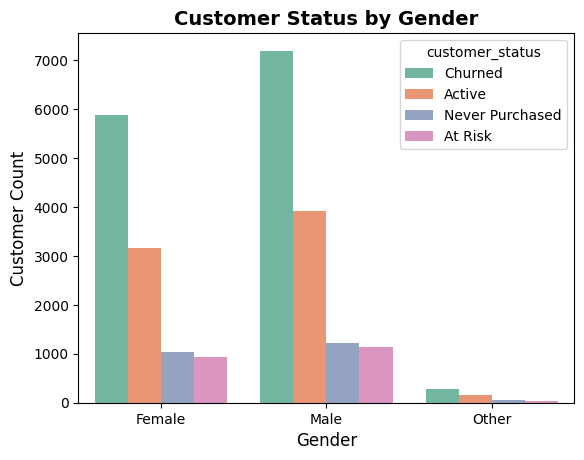

In [102]:
import matplotlib.pyplot as plt
df2 =c.groupby("gender")["customer_status"].value_counts().reset_index()
sns.barplot(data=df2,x="gender",y="count",hue="customer_status", palette="Set2")
plt.title("Customer Status by Gender", fontsize=14, fontweight="bold")
plt.xlabel("Gender", fontsize=12)
plt.ylabel("Customer Count", fontsize=12)
plt.show()

# male me hamare pass churn hue active , never purchase , at risk tino dono se jyda hai female or other se

In [103]:
df3 = c.groupby("state")["preferred_device"].value_counts()
df3

state           preferred_device
Andhra Pradesh  Mobile App           736
                Mobile Web           251
                Desktop              182
                Unknown                7
Bihar           Mobile App           274
                Mobile Web           109
                Desktop               47
                Unknown                1
Delhi           Mobile App           682
                Mobile Web           249
                Desktop              156
                Unknown                6
Gujarat         Mobile App          1614
                Mobile Web           597
                Desktop              358
                Unknown               14
Haryana         Mobile App           929
                Mobile Web           335
                Desktop              237
                Unknown                9
Karnataka       Mobile App          1257
                Mobile Web           430
                Desktop              281
                Unknown                5
Kerala          Mobile App           822
                Mobile Web           310
                Desktop              200
                Unknown                7
Madhya Pradesh  Mobile App           698
                Mobile Web           280
                Desktop              175
                Unknown                8
Maharashtra     Mobile App          2211
                Mobile Web           809
                Desktop              503
                Unknown               18
Punjab          Mobile App           705
                Mobile Web           267
                Desktop              162
                Unknown                3
Rajasthan       Mobile App           712
                Mobile Web           263
                Desktop              180
                Unknown                3
Tamil Nadu      Mobile App          1191
                Mobile Web           443
                Desktop              279
                Unknown               16
Telangana       Mobile App          1070
                Mobile Web           363
                Desktop              261
                Unknown                9
Uttar Pradesh   Mobile App          1734
                Mobile Web           624
                Desktop              406
                Unknown               12
West Bengal     Mobile App           914
                Mobile Web           320
                Desktop              249
                Unknown                7
Name: count, dtype: int64

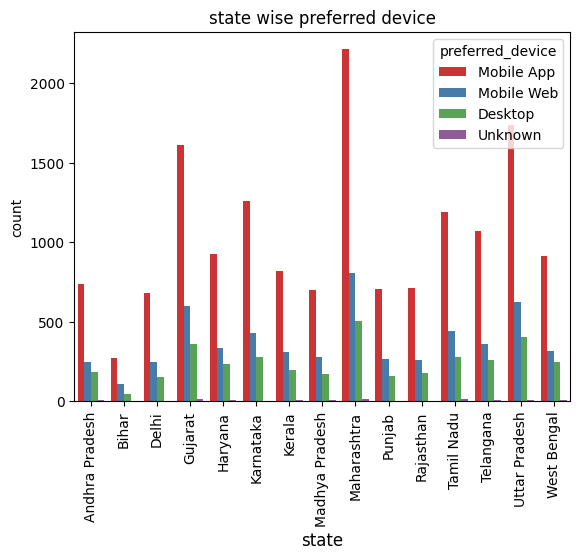

In [104]:
df3 = c.groupby("state")["preferred_device"].value_counts().reset_index()
sns.barplot(data=df3 , x="state" , y="count",hue="preferred_device" , palette="Set1")
plt.xticks(rotation = 90)
plt.title("state wise preferred device")
plt.xlabel("state",fontsize=12)
plt.ylabel("count")
plt.show()


# sabse jyada maharashtra state me sabse jyada preferred device hai jisme mobile app mobile web desktop , unknown hai
# or sabse kam bihar me hai

In [105]:
c.head(5)

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day,last_order_year,last_order_month,last_order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,2023-05-26,12294.86,Churned,Bronze,2023,1,9,2023.0,5.0,26.0
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,2024-05-23,53083.68,Churned,Gold,2023,4,10,2024.0,5.0,23.0
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,...,2025-07-14,11490.17,At Risk,Silver,2025,5,9,2025.0,7.0,14.0
3,CUST100003,2024-12-24,Female,34.0,25-34,Maharashtra,Pune,175,New,Mobile App,...,2025-12-19,3788.82,Active,Bronze,2024,12,24,2025.0,12.0,19.0
4,CUST100004,2023-08-15,Male,38.0,35-44,Andhra Pradesh,Visakhapatnam,446,Budget,Desktop,...,2023-11-01,30647.95,Churned,Silver,2023,8,15,2023.0,11.0,1.0


In [106]:
# city ke hisab se bhi dekh lete hai

df4 = c.groupby("city")["preferred_device"].value_counts()[:19]
df4

city       preferred_device
Ahmedabad  Mobile App          534
           Mobile Web          214
           Desktop             124
           Unknown               4
Amritsar   Mobile App          350
           Mobile Web          132
           Desktop              79
Bengaluru  Mobile App          634
           Mobile Web          196
           Desktop             141
           Unknown               2
Bhopal     Mobile App          355
           Mobile Web          135
           Desktop              85
           Unknown               3
Chennai    Mobile App          627
           Mobile Web          214
           Desktop             147
           Unknown               2
Name: count, dtype: int64

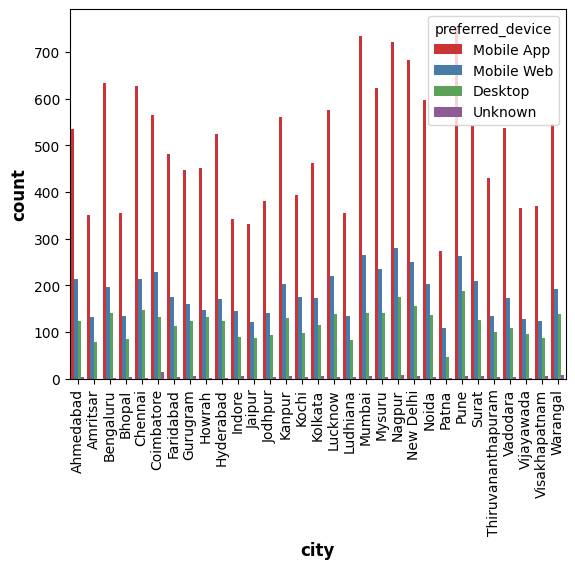

In [107]:
df4 = c.groupby("city")["preferred_device"].value_counts().reset_index()
sns.barplot(data=df4 , x="city" , y="count", hue="preferred_device",palette="Set1")
plt.xticks(rotation = 90)
plt.xlabel("city", fontsize = 12 , fontweight="bold")
plt.ylabel("count", fontsize = 12 , fontweight="bold")
plt.show()

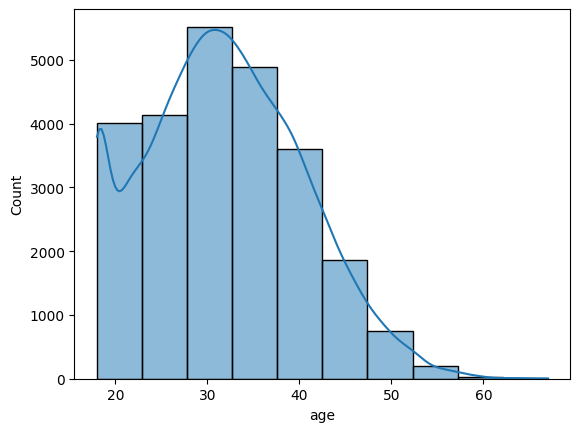

In [108]:
sns.histplot(data=c , x="age",bins=10,kde=True)
plt.show()

# sabse jyada 30 age wale jyada hai

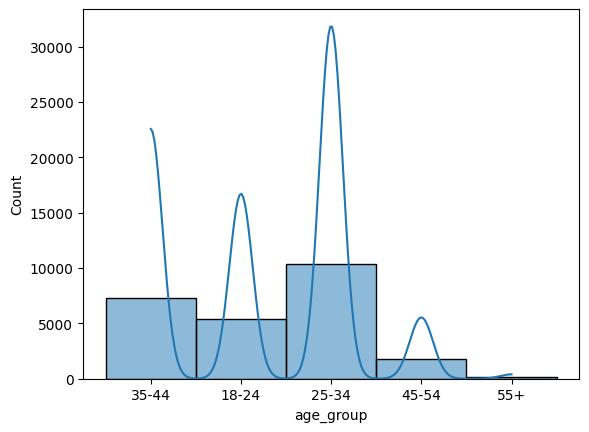

In [109]:
sns.histplot(data=c , x="age_group",bins=10,kde=True)
plt.show()

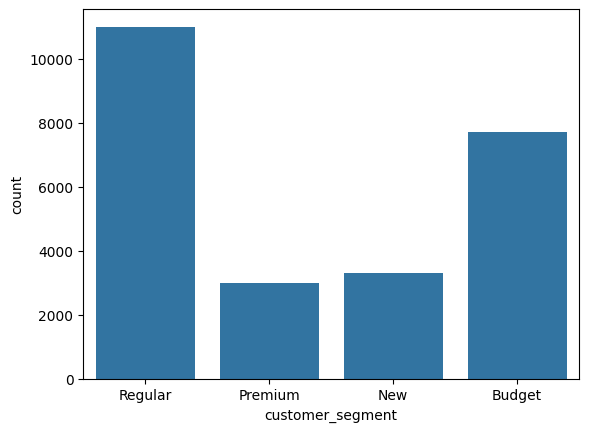

In [110]:
sns.countplot(data=c , x="customer_segment")
plt.show()

<Axes: xlabel='preferred_device', ylabel='count'>

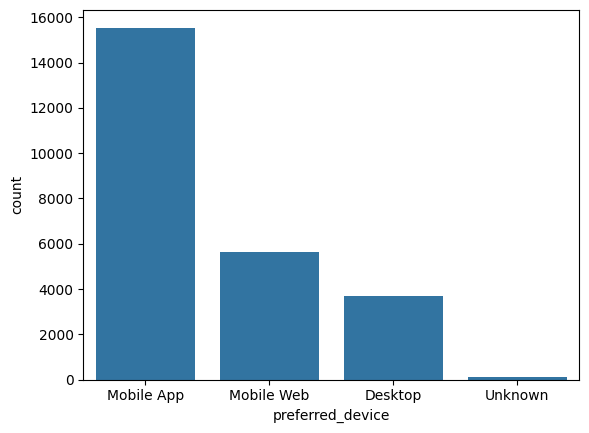

In [111]:
sns.countplot(data=c , x="preferred_device")


In [112]:
o

,order_id,customer_id,order_date,order_time,order_status,shipping_method,delivery_city,delivery_state,coupon_code,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,ORD1000000,CUST103868,2025-08-16,22:35:23,Failed,Next-Day,Mumbai,Maharashtra,FEST20,5.0,SMS Marketing,14439.90,0.0,722.00,15161.90,NaN,2025,8,16
1,ORD1000001,CUST118472,2023-02-11,18:51:17,Delivered,Economy/Surface,Thiruvananthapuram,Kerala,FEST20,15.0,Social Media - Facebook,4760.00,0.0,238.00,4998.00,CAMP1008,2023,2,11
2,ORD1000002,CUST120793,2024-12-14,11:08:38,Delivered,Economy/Surface,Nagpur,Maharashtra,APP5,30.0,Social Media - Instagram,826.00,0.0,41.30,867.30,CAMP1101,2024,12,14
3,ORD1000003,CUST109166,2025-11-23,09:32:24,Failed,Express,Kochi,Kerala,BIGBILLION,5.0,Direct/App,25878.00,0.0,1293.90,27171.90,NaN,2025,11,23
4,ORD1000004,CUST119895,2025-07-27,20:35:25,Cancelled,Standard,Jaipur,Rajasthan,SAVE15,30.0,Organic Search,3450.00,0.0,172.50,3622.50,NaN,2025,7,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,ORD1099995,CUST120257,2025-12-28,20:16:02,Processing,Next-Day,Nagpur,Maharashtra,FLAT50,10.0,Social Media - Facebook,12142.35,0.0,607.12,12749.47,NaN,2025,12,28
99996,ORD1099996,CUST107829,2024-09-02,14:27:56,Delivered,Economy/Surface,Vadodara,Gujarat,FEST20,15.0,Organic Search,21615.00,0.0,1080.75,22695.75,NaN,2024,9,2
99997,ORD1099997,CUST108115,2024-04-22,20:44:15,Delivered,Next-Day,Vadodara,Gujarat,FREESHIP,25.0,Social Media - Facebook,3957.60,0.0,197.88,4155.48,NaN,2024,4,22
99998,ORD1099998,CUST109794,2024-10-27,22:37:35,Delivered,Standard,Vadodara,Gujarat,NaN,20.0,Email Marketing,10518.70,0.0,525.94,11044.64,NaN,2024,10,27


In [113]:
merge1 = c.merge(o,on="customer_id",how="inner")

In [114]:
merge1

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,15.0,Affiliate,3986.5,0.0,199.32,4185.82,NaN,2023,2,28
1,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,0.0,Affiliate,450.0,49.0,22.50,521.50,NaN,2023,5,26
2,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,10.0,Affiliate,30645.0,0.0,1532.25,32177.25,NaN,2023,4,26
3,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,20.0,Organic Search,1760.0,0.0,88.00,1848.00,NaN,2023,4,30
4,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,15.0,Organic Search,24403.9,0.0,1220.20,25624.10,NaN,2023,8,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,CUST124997,2025-11-01,Male,18.0,18-24,Punjab,Ludhiana,668,Regular,Mobile App,...,0.0,Organic Search,24900.0,0.0,1245.00,26145.00,NaN,2025,11,16
99996,CUST124997,2025-11-01,Male,18.0,18-24,Punjab,Ludhiana,668,Regular,Mobile App,...,25.0,Organic Search,11882.4,0.0,594.12,12476.52,CAMP1151,2025,12,12
99997,CUST124997,2025-11-01,Male,18.0,18-24,Punjab,Ludhiana,668,Regular,Mobile App,...,10.0,Social Media - Instagram,100791.0,0.0,5039.55,105830.55,NaN,2025,11,23
99998,CUST124999,2025-11-23,Female,51.0,45-54,West Bengal,Kolkata,348,Budget,Mobile Web,...,15.0,Paid Search,3612.5,0.0,180.62,3793.12,NaN,2025,12,19


In [115]:
merge1.isnull().sum()

,0
customer_id,0
customer_signup_date,0
gender,0
age,0
age_group,0
state,0
city,0
pincode_prefix,0
customer_segment,0
preferred_device,0


In [116]:
merge1.head(5)

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,15.0,Affiliate,3986.5,0.0,199.32,4185.82,NaN,2023,2,28
1,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,0.0,Affiliate,450.0,49.0,22.50,521.50,NaN,2023,5,26
2,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,10.0,Affiliate,30645.0,0.0,1532.25,32177.25,NaN,2023,4,26
3,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,20.0,Organic Search,1760.0,0.0,88.00,1848.00,NaN,2023,4,30
4,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,15.0,Organic Search,24403.9,0.0,1220.20,25624.10,NaN,2023,8,27


In [117]:
df5 = merge1.groupby("gender")["final_amount"].sum()
df5

,final_amount
gender,
Female,1.136254e+09
Male,1.378482e+09
Other,5.785674e+07


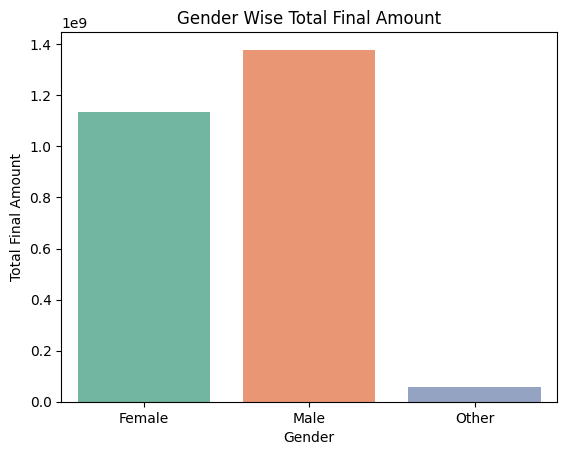

In [118]:
df5 = merge1.groupby("gender")["final_amount"].sum().reset_index()
sns.barplot(data=df5,x="gender",y="final_amount", palette="Set2")
plt.xlabel("Gender")
plt.ylabel("Total Final Amount")
plt.title("Gender Wise Total Final Amount")
plt.show()


# male ne sabse jyada order kiye hai

In [119]:
df5 = merge1.groupby("gender")["final_amount"].count()
df5

,final_amount
gender,
Female,44029
Male,53738
Other,2233


In [120]:
merge1.head(5)

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,15.0,Affiliate,3986.5,0.0,199.32,4185.82,NaN,2023,2,28
1,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,0.0,Affiliate,450.0,49.0,22.50,521.50,NaN,2023,5,26
2,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,10.0,Affiliate,30645.0,0.0,1532.25,32177.25,NaN,2023,4,26
3,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,20.0,Organic Search,1760.0,0.0,88.00,1848.00,NaN,2023,4,30
4,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,15.0,Organic Search,24403.9,0.0,1220.20,25624.10,NaN,2023,8,27


In [121]:
df6 = merge1.groupby("customer_segment")["final_amount"].sum()
df6

,final_amount
customer_segment,
Budget,3.609208e+08
New,7.606627e+07
Premium,8.838285e+08
Regular,1.251777e+09


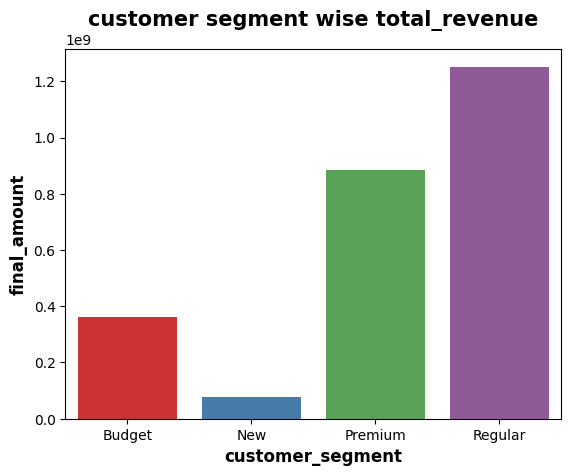

In [122]:
df6 = merge1.groupby("customer_segment")["final_amount"].sum().reset_index()
sns.barplot(data=df6 , x="customer_segment" , y="final_amount" , palette="Set1")
plt.xlabel("customer_segment", fontsize=12 , fontweight="bold")
plt.ylabel("final_amount",fontsize= 12 , fontweight="bold")
plt.title("customer segment wise total_revenue",fontsize=15 , fontweight="bold")
plt.show()

In [123]:
df7 = merge1.groupby("customer_segment")["preferred_device"].value_counts()
df7

customer_segment  preferred_device
Budget            Mobile App          10076
                  Mobile Web           3721
                  Desktop              2422
                  Unknown               111
New               Mobile App           2207
                  Mobile Web            838
                  Desktop               506
                  Unknown                23
Premium           Mobile App          18524
                  Mobile Web           6346
                  Desktop              4871
                  Unknown               144
Regular           Mobile App          31351
                  Mobile Web          11453
                  Desktop              7197
                  Unknown               210
Name: count, dtype: int64

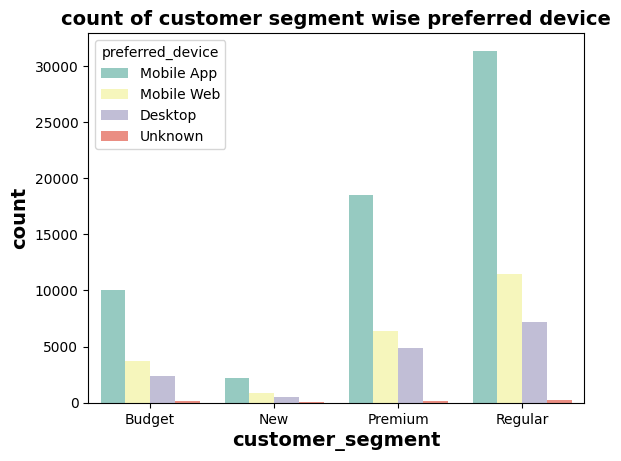

In [124]:
df7 = merge1.groupby("customer_segment")["preferred_device"].value_counts().reset_index()
sns.barplot(data=df7 ,x="customer_segment",y="count",hue="preferred_device" ,palette="Set3")
plt.xlabel("customer_segment" , fontsize=14 ,fontweight="bold")
plt.ylabel("count" , fontsize=14 ,fontweight="bold")
plt.title("count of customer segment wise preferred device" , fontsize=14 ,fontweight="bold")
plt.show()

In [125]:
merge1.head(5)

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,15.0,Affiliate,3986.5,0.0,199.32,4185.82,NaN,2023,2,28
1,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,0.0,Affiliate,450.0,49.0,22.50,521.50,NaN,2023,5,26
2,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,10.0,Affiliate,30645.0,0.0,1532.25,32177.25,NaN,2023,4,26
3,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,20.0,Organic Search,1760.0,0.0,88.00,1848.00,NaN,2023,4,30
4,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,15.0,Organic Search,24403.9,0.0,1220.20,25624.10,NaN,2023,8,27


In [126]:
df8 = merge1.groupby("preferred_device")["final_amount"].sum()
df8

,final_amount
preferred_device,
Desktop,3.866396e+08
Mobile App,1.598362e+09
Mobile Web,5.759077e+08
Unknown,1.168302e+07


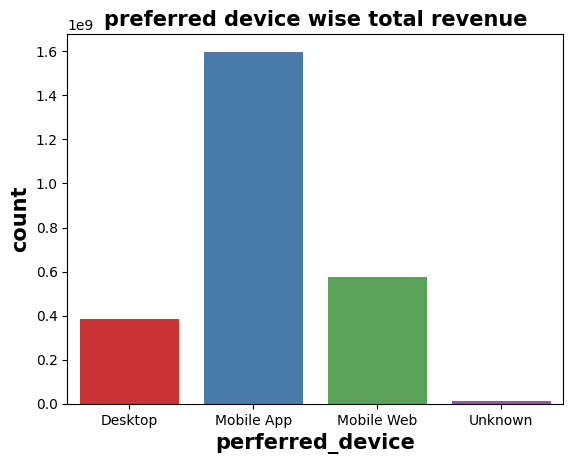

In [127]:
df8 = merge1.groupby("preferred_device")["final_amount"].sum().reset_index()
sns.barplot(data=df8, x="preferred_device",y="final_amount",palette="Set1")
plt.xlabel("perferred_device" , fontsize=15 , fontweight="bold")
plt.ylabel("count" , fontsize=15 , fontweight="bold")
plt.title("preferred device wise total revenue", fontsize=15 , fontweight="bold")
plt.show()

In [128]:
df9 = merge1.groupby("customer_segment")["shipping_fee"].sum()
df9

,shipping_fee
customer_segment,
Budget,43879.0
New,10852.0
Premium,36600.0
Regular,107077.0


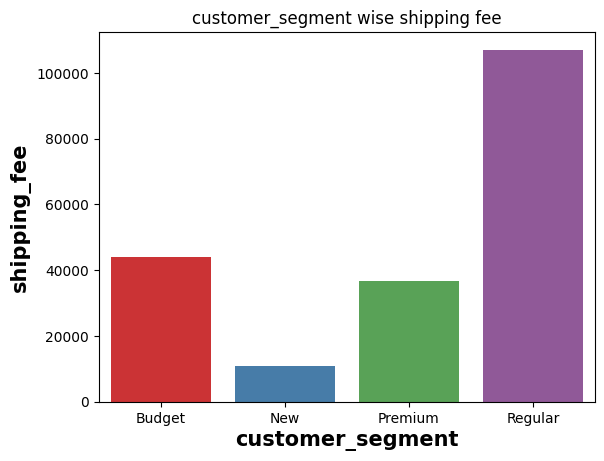

In [129]:
df9 = merge1.groupby("customer_segment")["shipping_fee"].sum().reset_index()
sns.barplot(data=df9 , x="customer_segment", y="shipping_fee" ,palette="Set1")
plt.xlabel("customer_segment" , fontsize=15 , fontweight= "bold")
plt.ylabel("shipping_fee" , fontsize=15 , fontweight= "bold")
plt.title("customer_segment wise shipping fee")
plt.show()

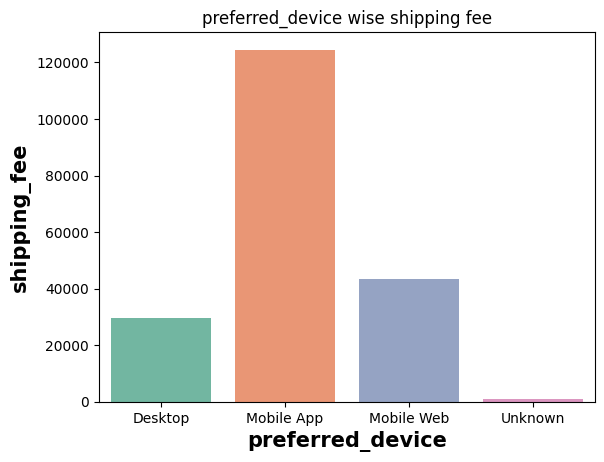

In [130]:
df9 = merge1.groupby("preferred_device")["shipping_fee"].sum().reset_index()
sns.barplot(data=df9 , x="preferred_device", y="shipping_fee" ,palette="Set2")
plt.xlabel("preferred_device" , fontsize=15 , fontweight= "bold")
plt.ylabel("shipping_fee" , fontsize=15 , fontweight= "bold")
plt.title("preferred_device wise shipping fee")
plt.show()

In [131]:
merge1.head(5)

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,15.0,Affiliate,3986.5,0.0,199.32,4185.82,NaN,2023,2,28
1,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,0.0,Affiliate,450.0,49.0,22.50,521.50,NaN,2023,5,26
2,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,10.0,Affiliate,30645.0,0.0,1532.25,32177.25,NaN,2023,4,26
3,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,20.0,Organic Search,1760.0,0.0,88.00,1848.00,NaN,2023,4,30
4,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,15.0,Organic Search,24403.9,0.0,1220.20,25624.10,NaN,2023,8,27


In [132]:
merge1.columns

Index(['customer_id', 'customer_signup_date', 'gender', 'age', 'age_group',
       'state', 'city', 'pincode_prefix', 'customer_segment',
       'preferred_device', 'preferred_payment_method', 'acquisition_channel',
       'total_orders', 'total_spend', 'last_order_date', 'average_order_value',
       'customer_status', 'loyalty_tier', 'customer_signup_year',
       'customer_signup_month', 'customer_signup_day', 'last_order_year',
       'last_order_month', 'last_order_day', 'order_id', 'order_date',
       'order_time', 'order_status', 'shipping_method', 'delivery_city',
       'delivery_state', 'coupon_code', 'discount_percentage',
       'marketing_channel', 'subtotal', 'shipping_fee', 'tax_amount',
       'final_amount', 'campaign_id', 'order_year', 'order_month',
       'order_day'],
      dtype='object')

In [133]:
# CUSTOMER SEGMENT WISE TOTAL ORDER
df9 = merge1.groupby("customer_segment")["order_id"].nunique()
df9

,order_id
customer_segment,
Budget,16330
New,3574
Premium,29885
Regular,50211


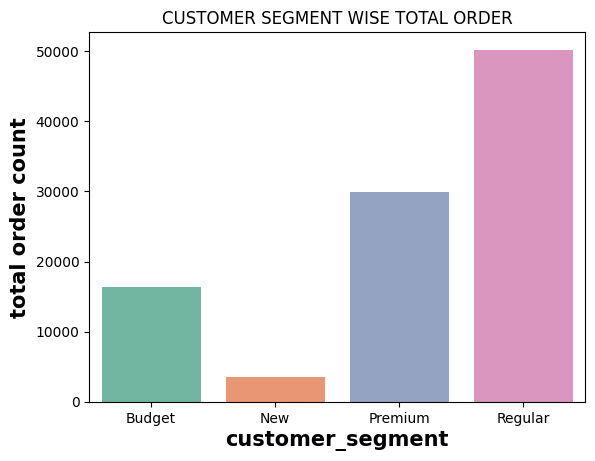

In [134]:
df9 = merge1.groupby("customer_segment")["order_id"].nunique().reset_index()
sns.barplot(data=df9 ,x="customer_segment",y="order_id",palette="Set2")
plt.xlabel("customer_segment" , fontsize=15 ,fontweight="bold")
plt.ylabel("total order count",fontsize=15 ,fontweight="bold")
plt.title("CUSTOMER SEGMENT WISE TOTAL ORDER")
plt.show()

In [135]:
merge1["order_status"]

,order_status
0,Delivered
1,Delivered
2,Cancelled
3,Delivered
4,Delivered
...,...
99995,Delivered
99996,Delivered
99997,Delivered
99998,Delivered


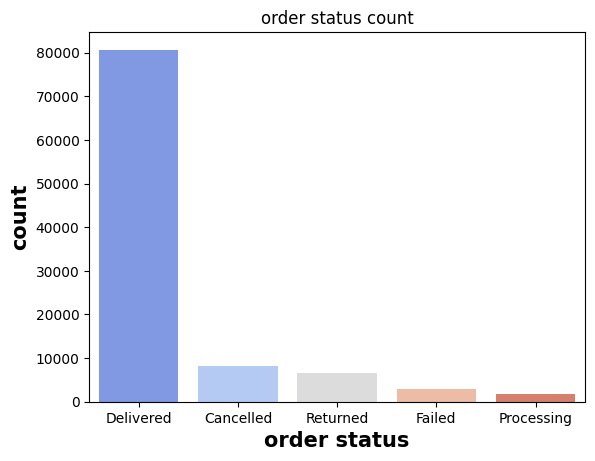

In [136]:
sns.countplot(data=merge1 , x="order_status",palette="coolwarm")
plt.xlabel("order status", fontsize=15 , fontweight="bold")
plt.ylabel("count", fontsize=15 , fontweight="bold")
plt.title("order status count")
plt.show()

In [137]:
merge1.columns

Index(['customer_id', 'customer_signup_date', 'gender', 'age', 'age_group',
       'state', 'city', 'pincode_prefix', 'customer_segment',
       'preferred_device', 'preferred_payment_method', 'acquisition_channel',
       'total_orders', 'total_spend', 'last_order_date', 'average_order_value',
       'customer_status', 'loyalty_tier', 'customer_signup_year',
       'customer_signup_month', 'customer_signup_day', 'last_order_year',
       'last_order_month', 'last_order_day', 'order_id', 'order_date',
       'order_time', 'order_status', 'shipping_method', 'delivery_city',
       'delivery_state', 'coupon_code', 'discount_percentage',
       'marketing_channel', 'subtotal', 'shipping_fee', 'tax_amount',
       'final_amount', 'campaign_id', 'order_year', 'order_month',
       'order_day'],
      dtype='object')

In [138]:
merge1["shipping_method"]

,shipping_method
0,Economy/Surface
1,Standard
2,Standard
3,Standard
4,Express
...,...
99995,Standard
99996,Express
99997,Next-Day
99998,Standard


In [139]:
merge1["shipping_method"].value_counts()

,count
shipping_method,
Standard,44852
Express,20262
Next-Day,15026
Economy/Surface,14920
Same-Day,4940


In [140]:
df10 = merge1.groupby("city")["final_amount"].sum().sort_values(ascending=False)[:5]
df10

,final_amount
city,
Mumbai,1.230407e+08
Pune,1.199221e+08
Nagpur,1.168860e+08
New Delhi,1.163086e+08
Mysuru,1.057062e+08


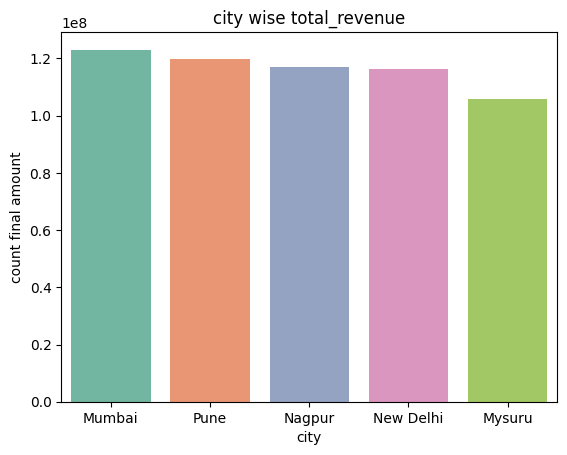

In [141]:
df10 = merge1.groupby("city")["final_amount"].sum().sort_values(ascending=False).reset_index()[:5]
sns.barplot(data=df10 ,x="city" ,y="final_amount" ,palette="Set2")
pls.xlabel("city")
pls.ylabel("count final amount")
plt.title("city wise total_revenue")
plt.show()

In [142]:
# shipping method wise total revenue
df11 = merge1.groupby("shipping_method")["final_amount"].sum().sort_values(ascending=False)
df11

,final_amount
shipping_method,
Standard,1.144411e+09
Express,5.301699e+08
Next-Day,3.862368e+08
Economy/Surface,3.814477e+08
Same-Day,1.303268e+08


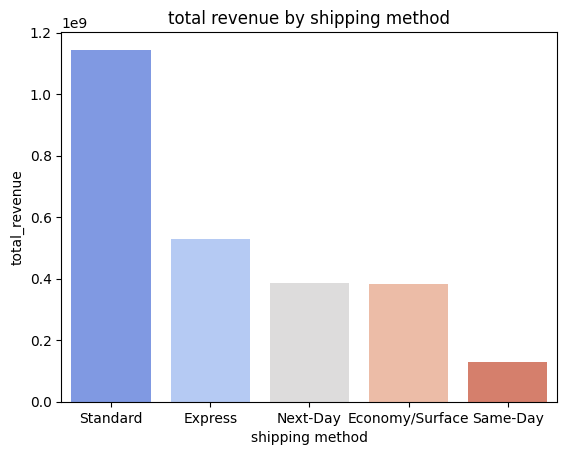

In [143]:
df11 = merge1.groupby("shipping_method")["final_amount"].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=df11 ,x="shipping_method" ,y="final_amount" , palette="coolwarm")
pls.xlabel("shipping method")
pls.ylabel("total_revenue")
pls.title("total revenue by shipping method")
plt.show()

In [144]:
merge1.columns

Index(['customer_id', 'customer_signup_date', 'gender', 'age', 'age_group',
       'state', 'city', 'pincode_prefix', 'customer_segment',
       'preferred_device', 'preferred_payment_method', 'acquisition_channel',
       'total_orders', 'total_spend', 'last_order_date', 'average_order_value',
       'customer_status', 'loyalty_tier', 'customer_signup_year',
       'customer_signup_month', 'customer_signup_day', 'last_order_year',
       'last_order_month', 'last_order_day', 'order_id', 'order_date',
       'order_time', 'order_status', 'shipping_method', 'delivery_city',
       'delivery_state', 'coupon_code', 'discount_percentage',
       'marketing_channel', 'subtotal', 'shipping_fee', 'tax_amount',
       'final_amount', 'campaign_id', 'order_year', 'order_month',
       'order_day'],
      dtype='object')

In [145]:
cr.head()

,review_id,order_id,customer_id,product_id,review_date,rating,review_sentiment,verified_purchase,year,month,day
0,REV100000,ORD1000002,CUST120793,PROD10470,2024-12-30,4,Positive,True,2024,12,30
1,REV100001,ORD1000005,CUST123408,PROD10085,2025-02-04,4,Positive,True,2025,2,4
2,REV100002,ORD1000005,CUST123408,PROD10233,2025-01-27,5,Positive,True,2025,1,27
3,REV100003,ORD1000006,CUST117355,PROD10176,2025-06-11,4,Positive,True,2025,6,11
4,REV100004,ORD1000006,CUST117355,PROD10210,2025-06-06,3,Neutral,True,2025,6,6


In [146]:
o.head()

,order_id,customer_id,order_date,order_time,order_status,shipping_method,delivery_city,delivery_state,coupon_code,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,ORD1000000,CUST103868,2025-08-16,22:35:23,Failed,Next-Day,Mumbai,Maharashtra,FEST20,5.0,SMS Marketing,14439.9,0.0,722.0,15161.9,NaN,2025,8,16
1,ORD1000001,CUST118472,2023-02-11,18:51:17,Delivered,Economy/Surface,Thiruvananthapuram,Kerala,FEST20,15.0,Social Media - Facebook,4760.0,0.0,238.0,4998.0,CAMP1008,2023,2,11
2,ORD1000002,CUST120793,2024-12-14,11:08:38,Delivered,Economy/Surface,Nagpur,Maharashtra,APP5,30.0,Social Media - Instagram,826.0,0.0,41.3,867.3,CAMP1101,2024,12,14
3,ORD1000003,CUST109166,2025-11-23,09:32:24,Failed,Express,Kochi,Kerala,BIGBILLION,5.0,Direct/App,25878.0,0.0,1293.9,27171.9,NaN,2025,11,23
4,ORD1000004,CUST119895,2025-07-27,20:35:25,Cancelled,Standard,Jaipur,Rajasthan,SAVE15,30.0,Organic Search,3450.0,0.0,172.5,3622.5,NaN,2025,7,27


In [147]:
oi.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,OI10000000,ORD1000000,PROD10347,4,150.0,6.5,561.0,515.92,45.08
1,OI10000001,ORD1000000,PROD10510,1,1150.0,5.0,1092.5,752.18,340.32
2,OI10000002,ORD1000000,PROD10305,2,960.0,8.0,1766.4,1217.66,548.74
3,OI10000003,ORD1000000,PROD10092,4,920.0,5.0,3496.0,3049.52,446.48
4,OI10000004,ORD1000000,PROD10417,3,2640.0,5.0,7524.0,6847.65,676.35


In [148]:
c["total_orders"]

,total_orders
0,3
1,7
2,10
3,1
4,2
...,...
24995,0
24996,12
24997,4
24998,0


In [149]:
df12 = merge1.groupby("customer_segment")["total_orders"].sum().sort_values(ascending=False)
df12

,total_orders
customer_segment,
Premium,323658
Regular,287598
Budget,50570
New,7167


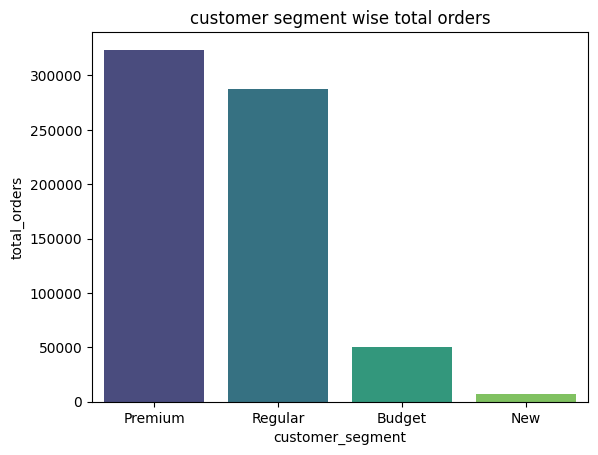

In [150]:
df12 = merge1.groupby("customer_segment")["total_orders"].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=df12 ,x="customer_segment",y="total_orders",palette="viridis")
pls.xlabel("customer_segment")
pls.ylabel("total_orders")
plt.title("customer segment wise total orders")
plt.show()

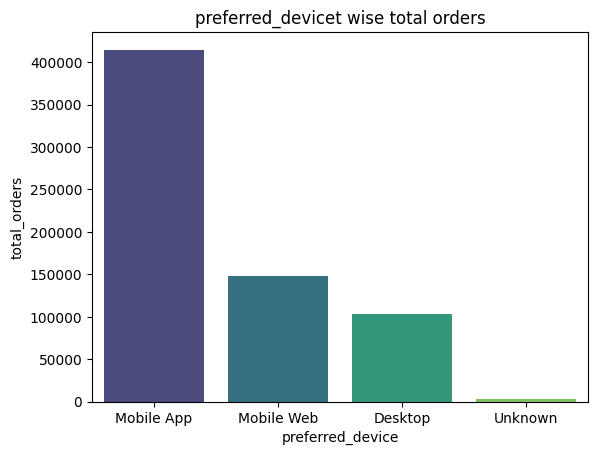

In [151]:
df12 = merge1.groupby("preferred_device")["total_orders"].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=df12 ,x="preferred_device",y="total_orders",palette="viridis")
pls.xlabel("preferred_device")
pls.ylabel("total_orders")
plt.title("preferred_devicet wise total orders")
plt.show()

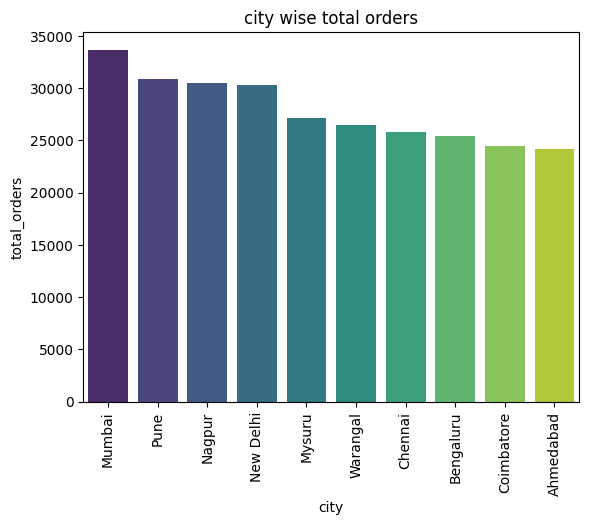

In [152]:
df12 = merge1.groupby("city")["total_orders"].sum().sort_values(ascending=False).reset_index().head(10)
sns.barplot(data=df12 ,x="city",y="total_orders",palette="viridis")
pls.xticks(rotation=90)
pls.xlabel("city")
pls.ylabel("total_orders")
plt.title("city wise total orders")
plt.show()

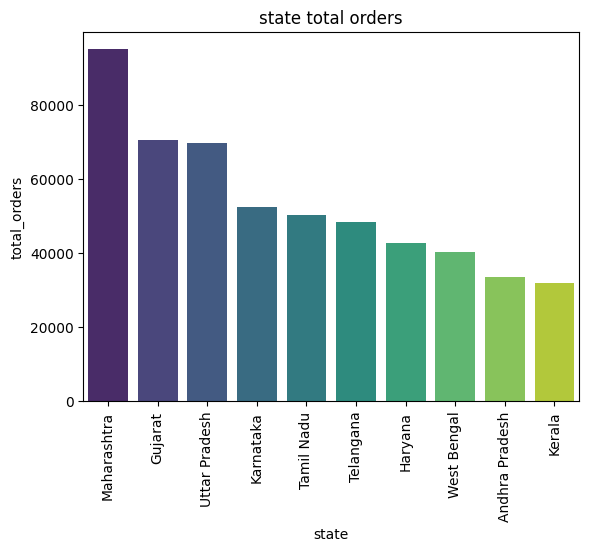

In [153]:
df12 = merge1.groupby("state")["total_orders"].sum().sort_values(ascending=False).reset_index().head(10)
sns.barplot(data=df12 ,x="state",y="total_orders",palette="viridis")
pls.xticks(rotation=90)
pls.xlabel("state")
pls.ylabel("total_orders")
plt.title("state total orders")
plt.show()

In [154]:
c.head()

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day,last_order_year,last_order_month,last_order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,2023-05-26,12294.86,Churned,Bronze,2023,1,9,2023.0,5.0,26.0
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,2024-05-23,53083.68,Churned,Gold,2023,4,10,2024.0,5.0,23.0
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,...,2025-07-14,11490.17,At Risk,Silver,2025,5,9,2025.0,7.0,14.0
3,CUST100003,2024-12-24,Female,34.0,25-34,Maharashtra,Pune,175,New,Mobile App,...,2025-12-19,3788.82,Active,Bronze,2024,12,24,2025.0,12.0,19.0
4,CUST100004,2023-08-15,Male,38.0,35-44,Andhra Pradesh,Visakhapatnam,446,Budget,Desktop,...,2023-11-01,30647.95,Churned,Silver,2023,8,15,2023.0,11.0,1.0


In [155]:
oi.head()

,order_item_id,order_id,product_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,OI10000000,ORD1000000,PROD10347,4,150.0,6.5,561.0,515.92,45.08
1,OI10000001,ORD1000000,PROD10510,1,1150.0,5.0,1092.5,752.18,340.32
2,OI10000002,ORD1000000,PROD10305,2,960.0,8.0,1766.4,1217.66,548.74
3,OI10000003,ORD1000000,PROD10092,4,920.0,5.0,3496.0,3049.52,446.48
4,OI10000004,ORD1000000,PROD10417,3,2640.0,5.0,7524.0,6847.65,676.35


In [156]:
c.head()

,customer_id,customer_signup_date,gender,age,age_group,state,city,pincode_prefix,customer_segment,preferred_device,...,last_order_date,average_order_value,customer_status,loyalty_tier,customer_signup_year,customer_signup_month,customer_signup_day,last_order_year,last_order_month,last_order_day
0,CUST100000,2023-01-09,Male,44.0,35-44,Madhya Pradesh,Indore,607,Regular,Mobile App,...,2023-05-26,12294.86,Churned,Bronze,2023,1,9,2023.0,5.0,26.0
1,CUST100001,2023-04-10,Male,20.0,18-24,West Bengal,Kolkata,245,Regular,Mobile App,...,2024-05-23,53083.68,Churned,Gold,2023,4,10,2024.0,5.0,23.0
2,CUST100002,2025-05-09,Female,35.0,35-44,Gujarat,Ahmedabad,160,Premium,Mobile Web,...,2025-07-14,11490.17,At Risk,Silver,2025,5,9,2025.0,7.0,14.0
3,CUST100003,2024-12-24,Female,34.0,25-34,Maharashtra,Pune,175,New,Mobile App,...,2025-12-19,3788.82,Active,Bronze,2024,12,24,2025.0,12.0,19.0
4,CUST100004,2023-08-15,Male,38.0,35-44,Andhra Pradesh,Visakhapatnam,446,Budget,Desktop,...,2023-11-01,30647.95,Churned,Silver,2023,8,15,2023.0,11.0,1.0


In [157]:
o.head(

)

,order_id,customer_id,order_date,order_time,order_status,shipping_method,delivery_city,delivery_state,coupon_code,discount_percentage,marketing_channel,subtotal,shipping_fee,tax_amount,final_amount,campaign_id,order_year,order_month,order_day
0,ORD1000000,CUST103868,2025-08-16,22:35:23,Failed,Next-Day,Mumbai,Maharashtra,FEST20,5.0,SMS Marketing,14439.9,0.0,722.0,15161.9,NaN,2025,8,16
1,ORD1000001,CUST118472,2023-02-11,18:51:17,Delivered,Economy/Surface,Thiruvananthapuram,Kerala,FEST20,15.0,Social Media - Facebook,4760.0,0.0,238.0,4998.0,CAMP1008,2023,2,11
2,ORD1000002,CUST120793,2024-12-14,11:08:38,Delivered,Economy/Surface,Nagpur,Maharashtra,APP5,30.0,Social Media - Instagram,826.0,0.0,41.3,867.3,CAMP1101,2024,12,14
3,ORD1000003,CUST109166,2025-11-23,09:32:24,Failed,Express,Kochi,Kerala,BIGBILLION,5.0,Direct/App,25878.0,0.0,1293.9,27171.9,NaN,2025,11,23
4,ORD1000004,CUST119895,2025-07-27,20:35:25,Cancelled,Standard,Jaipur,Rajasthan,SAVE15,30.0,Organic Search,3450.0,0.0,172.5,3622.5,NaN,2025,7,27


In [158]:
pay.head()

,payment_id,order_id,payment_date,payment_method,payment_status,amount_paid,transaction_fee,refund_amount,payment_year,payment_month,payment_day
0,PAY1000000,ORD1000000,2025-08-16,EMI,Failed,0.0,0.0,0.0,2025,8,16
1,PAY1000001,ORD1000001,2023-02-12,UPI,Success,4998.0,0.0,0.0,2023,2,12
2,PAY1000002,ORD1000002,2024-12-14,Net Banking,Success,867.3,0.0,0.0,2024,12,14
3,PAY1000003,ORD1000003,2025-11-23,Cash on Delivery,Not Charged,0.0,0.0,0.0,2025,11,23
4,PAY1000004,ORD1000004,2025-07-27,Cash on Delivery,Not Charged,0.0,0.0,0.0,2025,7,27


In [159]:
p.head()

,product_id,product_name,category,subcategory,brand,price,cost_price,discount_range,rating_average,rating_count,stock_quantity,product_launch_date,product_type,return_rate_baseline,product_launch_year,product_launch_month,product_launch_day
0,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,1422,2025-12-12,Premium,0.0118,2025,12,12
1,PROD10001,Gupta-Chandra Essential Men's Bottomwear,Fashion,Men's Bottomwear,Gupta-Chandra,4060.0,2375.50,10-25%,5.0,13,1595,2023-09-01,Budget,0.1678,2023,9,1
2,PROD10002,"Murty, Advanced Women's Casual",Footwear,Women's Casual,"Murty,",2800.0,1740.98,25-40%,4.2,139,732,2024-12-24,Premium,0.2193,2024,12,24
3,PROD10003,Madan-Kanda Signature Bedding,Home & Kitchen,Bedding,Madan-Kanda,5680.0,4330.67,15-30%,4.1,31,1181,2024-03-28,Premium,0.0689,2024,3,28
4,PROD10004,"Sami, Premium Home Decor",Home & Kitchen,Home Decor,"Sami,",370.0,250.98,25-40%,4.5,279,2597,2024-02-03,Standard,0.0664,2024,2,3


In [160]:
merge2 = p.merge(oi,on="product_id",how="left")

In [161]:
merge2.head(5)

,product_id,product_name,category,subcategory,brand,price,cost_price,discount_range,rating_average,rating_count,...,product_launch_month,product_launch_day,order_item_id,order_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10004537,ORD1001781,3,220.0,28.0,475.2,521.64,-46.44
1,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10005449,ORD1002157,2,220.0,18.0,360.8,347.76,13.04
2,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10009119,ORD1003598,2,220.0,13.0,382.8,347.76,35.04
3,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10010407,ORD1004097,1,220.0,13.0,191.4,173.88,17.52
4,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10011299,ORD1004447,2,220.0,20.0,352.0,347.76,4.24


In [162]:
merge2.columns

Index(['product_id', 'product_name', 'category', 'subcategory', 'brand',
       'price', 'cost_price', 'discount_range', 'rating_average',
       'rating_count', 'stock_quantity', 'product_launch_date', 'product_type',
       'return_rate_baseline', 'product_launch_year', 'product_launch_month',
       'product_launch_day', 'order_item_id', 'order_id', 'quantity',
       'unit_price', 'discount_percentage', 'item_revenue', 'item_cost',
       'profit'],
      dtype='object')

In [163]:
# total revenue
a = merge2["item_revenue"].sum()
a

np.float64(2449898974.35)

In [164]:
# top 5 product by revenue
df13 = merge2.groupby("product_name")["item_revenue"].sum().sort_values(ascending=False).head(5)
df13

,item_revenue
product_name,
"Chaudhry, Advanced Smartwatche",5.207029e+08
"Mistry, Basic Large Appliance",1.089752e+08
Gandhi-Lanka Ultra Storage & Container,8.141222e+07
Kala-Vaidya Deluxe Laptop,7.203530e+07
"Boase, Ultra Air Conditioner",6.394125e+07


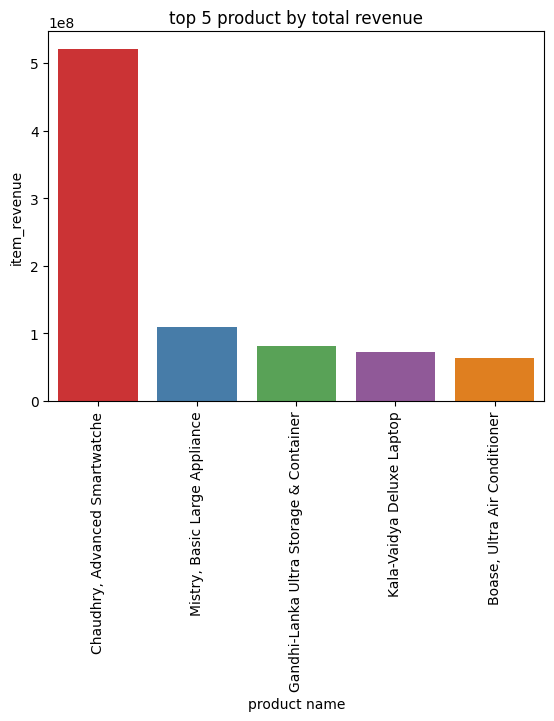

In [165]:
df13 = merge2.groupby("product_name")["item_revenue"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df13,x="product_name",y="item_revenue",palette="Set1")
plt.xticks(rotation=90)
plt.xlabel("product name")
plt.ylabel("item_revenue")
plt.title("top 5 product by total revenue")
plt.show()


In [166]:
merge2["category"].value_counts()

,count
category,
Fashion,42956
Home & Kitchen,26243
Electronics,25512
Health & Wellness,15697
Grocery,15638
Appliances,15607
Footwear,14115
Books,13223
Bags,12951


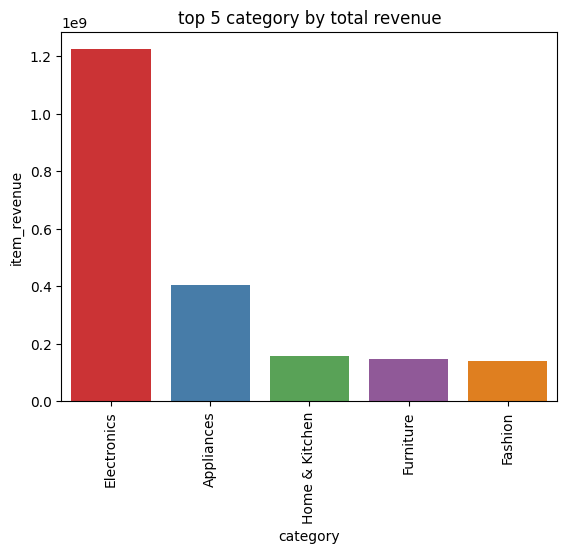

In [167]:
# top 10 category by total revenue

df13 = merge2.groupby("category")["item_revenue"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df13,x="category",y="item_revenue",palette="Set1")
plt.xticks(rotation=90)
plt.xlabel("category")
plt.ylabel("item_revenue")
plt.title("top 5 category by total revenue")
plt.show()

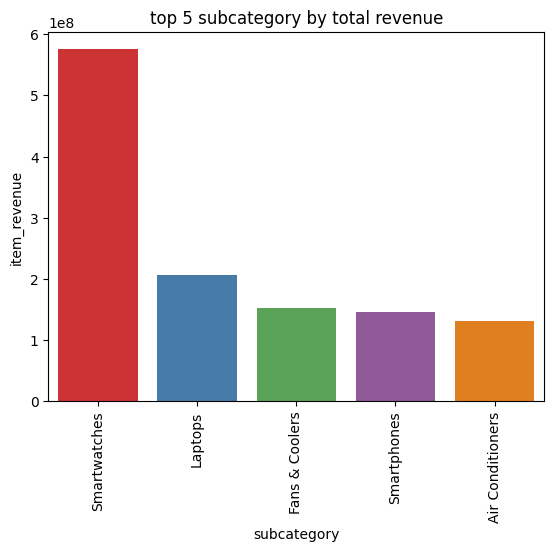

In [168]:
# top 10 subcategory by total revenue

df13 = merge2.groupby("subcategory")["item_revenue"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df13,x="subcategory",y="item_revenue",palette="Set1")
plt.xticks(rotation=90)
plt.xlabel("subcategory")
plt.ylabel("item_revenue")
plt.title("top 5 subcategory by total revenue")
plt.show()

In [169]:
merge2.columns

Index(['product_id', 'product_name', 'category', 'subcategory', 'brand',
       'price', 'cost_price', 'discount_range', 'rating_average',
       'rating_count', 'stock_quantity', 'product_launch_date', 'product_type',
       'return_rate_baseline', 'product_launch_year', 'product_launch_month',
       'product_launch_day', 'order_item_id', 'order_id', 'quantity',
       'unit_price', 'discount_percentage', 'item_revenue', 'item_cost',
       'profit'],
      dtype='object')

In [170]:
df14 = merge2.groupby("product_name")["quantity"].sum().sort_values(ascending=False).head(5)
df14

,quantity
product_name,
Chanda Deluxe Winter Wear,17710
"Solanki, Basic Winter Wear",14324
Soman Classic Comic,12888
"Memon, Compact Action Figure",11910
Gandhi-Lanka Ultra Storage & Container,11062


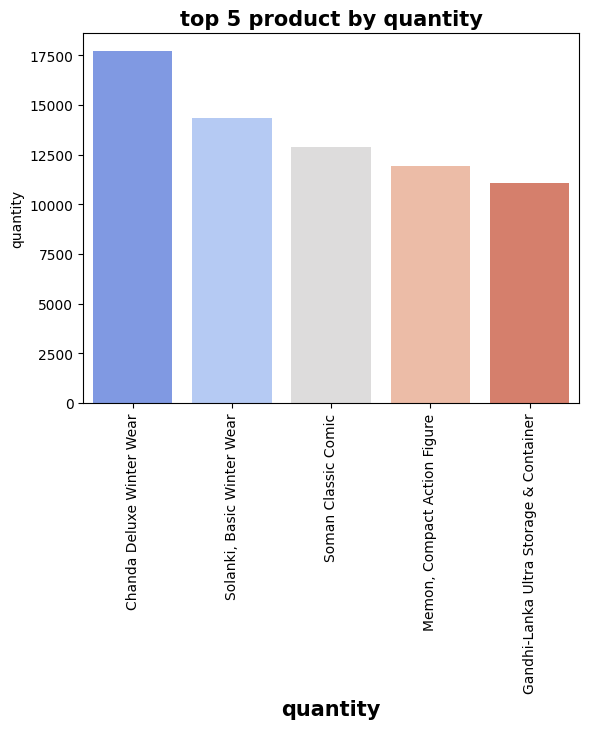

In [171]:
# top 5 product by quantity
df14 = merge2.groupby("product_name")["quantity"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df14,x="product_name",y="quantity",palette="coolwarm")
plt.xticks(rotation=90)
plt.xlabel("product name",fontsize=15,fontweight="bold")
plt.xlabel("quantity",fontsize=15,fontweight="bold")
plt.title("top 5 product by quantity",fontsize=15,fontweight="bold")
plt.show()

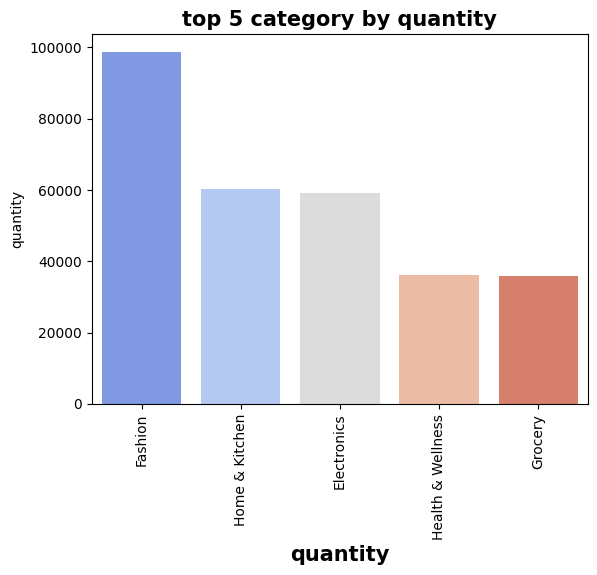

In [172]:
# top 5 category by quantity
df14 = merge2.groupby("category")["quantity"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df14,x="category",y="quantity",palette="coolwarm")
plt.xticks(rotation=90)
plt.xlabel("category",fontsize=15,fontweight="bold")
plt.xlabel("quantity",fontsize=15,fontweight="bold")
plt.title("top 5 category by quantity",fontsize=15,fontweight="bold")
plt.show()

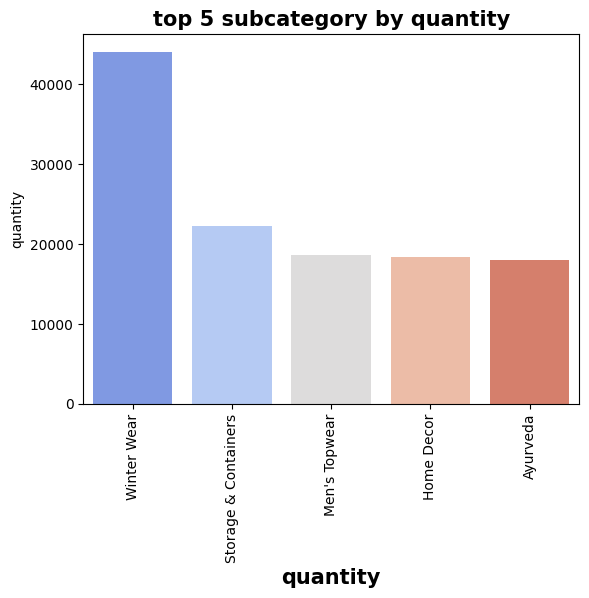

In [173]:
# top 5 subcategory by quantity
df14 = merge2.groupby("subcategory")["quantity"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df14,x="subcategory",y="quantity",palette="coolwarm")
plt.xticks(rotation=90)
plt.xlabel("subcategory",fontsize=15,fontweight="bold")
plt.xlabel("quantity",fontsize=15,fontweight="bold")
plt.title("top 5 subcategory by quantity",fontsize=15,fontweight="bold")
plt.show()

In [174]:
# Monthly Revenue Trend
df15 = merge2.groupby("product_launch_month")["item_revenue"].sum()
df15

,item_revenue
product_launch_month,
1,1.312550e+08
2,9.631523e+07
3,2.711155e+08
4,9.517948e+07
5,1.705133e+08
6,1.024854e+08
7,3.803701e+07
8,6.515708e+07
9,1.234689e+08


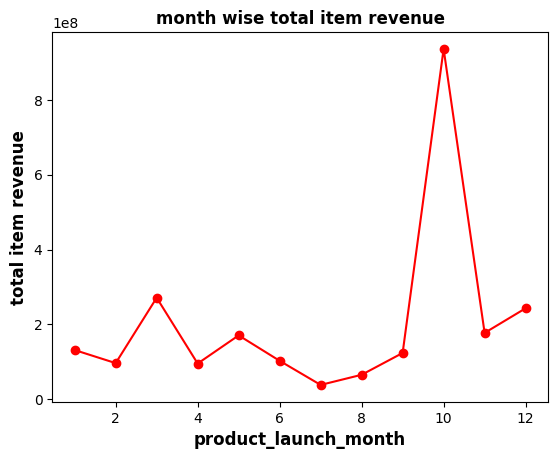

In [175]:
# monthly trend
df15 = merge2.groupby("product_launch_month")["item_revenue"].sum()
df15.plot(kind="line",marker="o",color="r")
plt.xlabel("product_launch_month",fontsize=12,fontweight="bold")
plt.ylabel("total item revenue",fontsize=12,fontweight="bold")
plt.title("month wise total item revenue",fontsize=12,fontweight="bold")
plt.show()

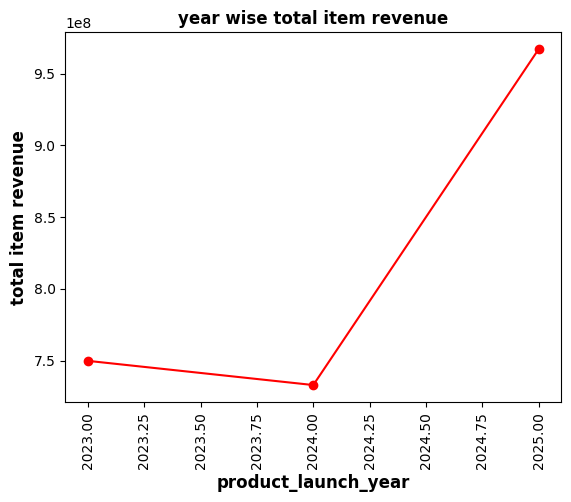

In [176]:
# yearly trend
df15 = merge2.groupby("product_launch_year")["item_revenue"].sum()
df15.plot(kind="line",marker="o",color="r")
plt.xticks(rotation=90)
plt.xlabel("product_launch_year",fontsize=12,fontweight="bold")
plt.ylabel("total item revenue",fontsize=12,fontweight="bold")
plt.title("year wise total item revenue",fontsize=12,fontweight="bold")
plt.show()

In [177]:
# TOTAL PROFIT
merge2["profit"].sum()

np.float64(197294347.02)

In [178]:
# profit margin

total_profit = merge2["profit"].sum()
total_revenue = merge2["item_revenue"].sum()
profit_margin = (total_profit / total_revenue)*100

profit_margin

np.float64(8.053162562441807)

In [179]:
# Har ₹100 ki revenue par 8.05 ka profit mil rha hai
total_profit = merge2["profit"].sum()
total_revenue = merge2["item_revenue"].sum()

profit_margin = (total_profit / total_revenue) * 100
print(round(profit_margin, 2))


8.05


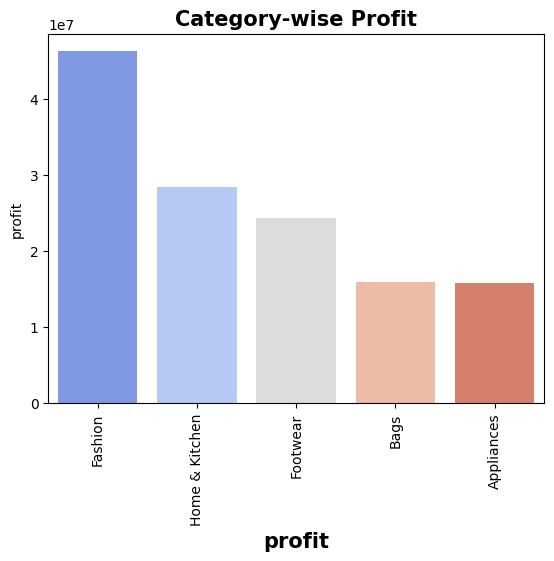

In [180]:
# Category wise Profit
df16 = merge2.groupby("category")["profit"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df16,x="category",y="profit",palette="coolwarm")
plt.xticks(rotation=90)
plt.xlabel("category",fontsize=15,fontweight="bold")
plt.xlabel("profit",fontsize=15,fontweight="bold")
plt.title("Category-wise Profit",fontsize=15,fontweight="bold")
plt.show()

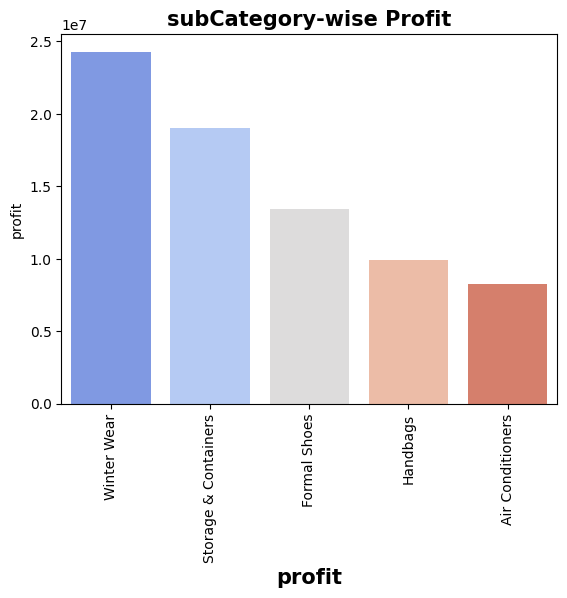

In [181]:
# subCategory wise Profit
df16 = merge2.groupby("subcategory")["profit"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df16,x="subcategory",y="profit",palette="coolwarm")
plt.xticks(rotation=90)
plt.xlabel("subcategory",fontsize=15,fontweight="bold")
plt.xlabel("profit",fontsize=15,fontweight="bold")
plt.title("subCategory-wise Profit",fontsize=15,fontweight="bold")
plt.show()

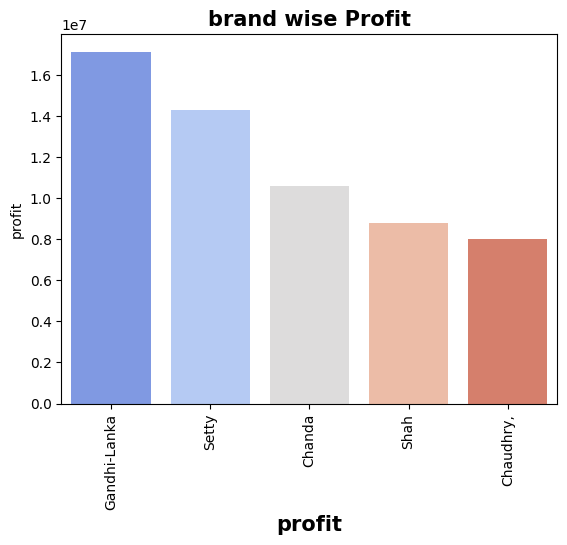

In [182]:
# brand wise Profit
df16 = merge2.groupby("brand")["profit"].sum().sort_values(ascending=False).reset_index().head(5)
sns.barplot(data=df16,x="brand",y="profit",palette="coolwarm")
plt.xticks(rotation=90)
plt.xlabel("brand",fontsize=15,fontweight="bold")
plt.xlabel("profit",fontsize=15,fontweight="bold")
plt.title("brand wise Profit",fontsize=15,fontweight="bold")
plt.show()

In [183]:
merge2.groupby("discount_range")["item_revenue"].sum().sort_values(ascending=False)

,item_revenue
discount_range,
25-40%,6.937098e+08
0-15%,5.188623e+08
20-35%,3.927327e+08
5-20%,2.777834e+08
30-45%,2.222641e+08
10-25%,1.739499e+08
15-30%,1.705968e+08


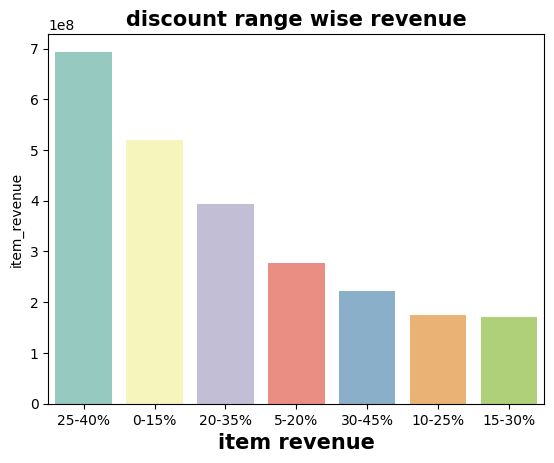

In [184]:
# Discount Analysis
df17 = merge2.groupby("discount_range")["item_revenue"].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=df17 ,x="discount_range",y="item_revenue",palette="Set3")
plt.xlabel("discount range",fontsize=15,fontweight="bold")
plt.xlabel("item revenue",fontsize=15,fontweight="bold")
plt.title("discount range wise revenue",fontsize=15,fontweight="bold")
plt.show()

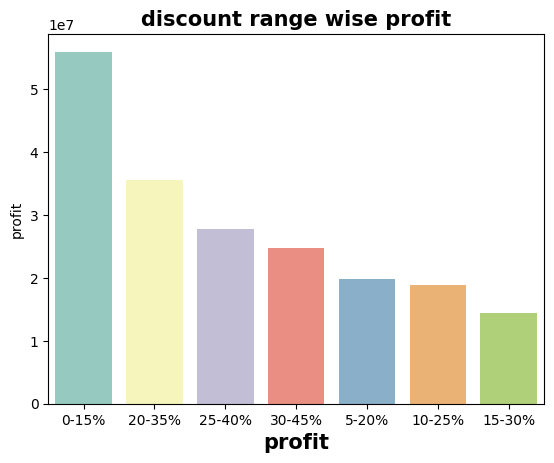

In [185]:
df17 = merge2.groupby("discount_range")["profit"].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=df17 ,x="discount_range",y="profit",palette="Set3")
plt.xlabel("discount range",fontsize=15,fontweight="bold")
plt.xlabel("profit",fontsize=15,fontweight="bold")
plt.title("discount range wise profit",fontsize=15,fontweight="bold")
plt.show()

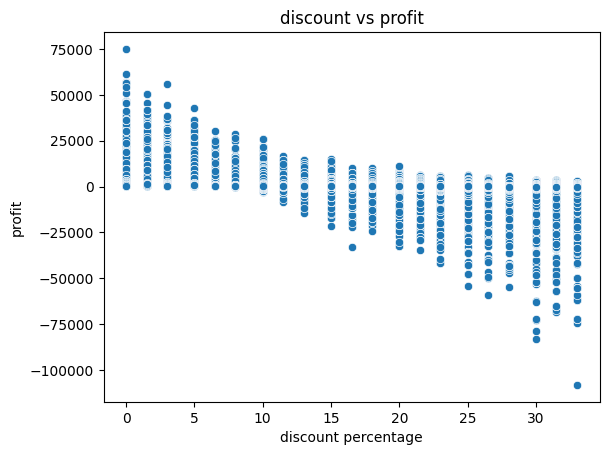

In [186]:
# discount percentage vs profit
sns.scatterplot(data=merge2 , x="discount_percentage",y="profit")
plt.xlabel("discount percentage")
plt.ylabel("profit")
plt.title("discount vs profit")
plt.show()

In [187]:
merge2.head(

)

,product_id,product_name,category,subcategory,brand,price,cost_price,discount_range,rating_average,rating_count,...,product_launch_month,product_launch_day,order_item_id,order_id,quantity,unit_price,discount_percentage,item_revenue,item_cost,profit
0,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10004537,ORD1001781,3,220.0,28.0,475.2,521.64,-46.44
1,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10005449,ORD1002157,2,220.0,18.0,360.8,347.76,13.04
2,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10009119,ORD1003598,2,220.0,13.0,382.8,347.76,35.04
3,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10010407,ORD1004097,1,220.0,13.0,191.4,173.88,17.52
4,PROD10000,Sen Basic Staple,Grocery,Staples,Sen,220.0,173.88,0-15%,4.4,32,...,12,12,OI10011299,ORD1004447,2,220.0,20.0,352.0,347.76,4.24


In [188]:
loss = merge2[merge2["profit"]< 0 ]
loss["profit"].sum()

np.float64(-84862150.74000001)

In [189]:
pr= merge2[merge2["profit"]> 0 ]
pr["profit"].sum()



np.float64(282156497.76)

In [190]:
r.head(5)

,return_id,order_id,customer_id,product_id,return_date,return_reason,refund_amount,return_status,return_year,return_month,return_day
0,RET100000,ORD1000009,CUST117396,PROD10073,2024-05-28,Changed mind,2094.4,Refund Completed,2024,5,28
1,RET100001,ORD1000019,CUST122124,PROD10077,2023-12-30,Product damaged,1040.0,Refund Completed,2023,12,30
2,RET100002,ORD1000019,CUST122124,PROD10451,2024-01-06,Wrong product,0.0,Pending,2024,1,6
3,RET100003,ORD1000019,CUST122124,PROD10043,2024-01-05,Quality issue,15104.0,Refund Completed,2024,1,5
4,RET100004,ORD1000028,CUST101962,PROD10171,2023-06-19,Changed mind,0.0,Pending,2023,6,19


In [191]:
r["return_reason"].value_counts()

,count
return_reason,
Size issue,2201
Changed mind,1984
Product damaged,1933
Quality issue,1692
Product not as expected,1442
Wrong product,1394
Late delivery,960
Other,469


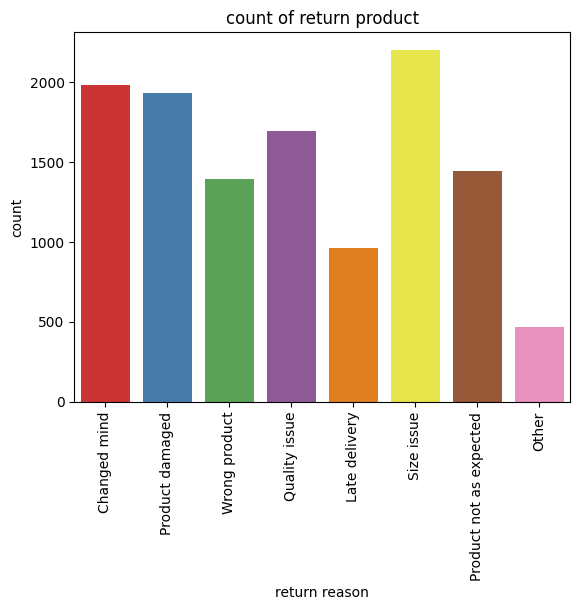

In [197]:
# count of return product
sns.countplot(data=r ,x=r["return_reason"],palette="Set1")
pls.xticks(rotation=90)
plt.xlabel("return reason")
plt.ylabel("count")
plt.title("count of return product")
plt.show()

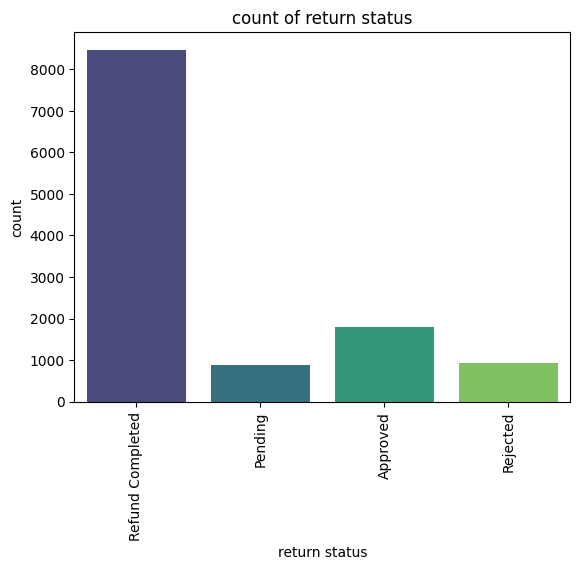

In [196]:
# count of return status
sns.countplot(data=r ,x=r["return_status"],palette="viridis")
pls.xticks(rotation=90)
plt.xlabel("return status")
plt.ylabel("count")
plt.title("count of return status")
plt.show()

In [199]:
df21= r.groupby("return_reason")["return_status"].value_counts()
df21

return_reason            return_status   
Changed mind             Refund Completed    1368
                         Approved             308
                         Pending              157
                         Rejected             151
Late delivery            Refund Completed     704
                         Approved             120
                         Pending               70
                         Rejected              66
Other                    Refund Completed     343
                         Approved              60
                         Rejected              37
                         Pending               29
Product damaged          Refund Completed    1368
                         Approved             292
                         Rejected             158
                         Pending              115
Product not as expected  Refund Completed     987
                         Approved             227
                         Rejected             115
                         Pending              113
Quality issue            Refund Completed    1189
                         Approved             260
                         Rejected             123
                         Pending              120
Size issue               Refund Completed    1536
                         Approved             308
                         Rejected             182
                         Pending              175
Wrong product            Refund Completed     978
                         Approved             217
                         Rejected             106
                         Pending               93
Name: count, dtype: int64

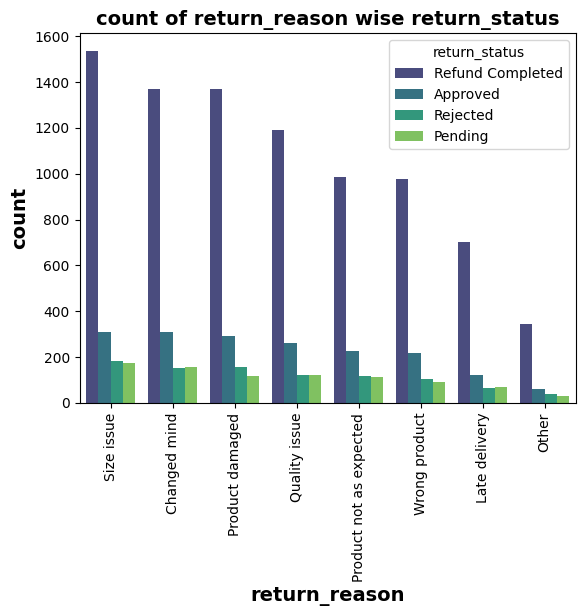

In [203]:
df21= r.groupby("return_reason")["return_status"].value_counts().sort_values(ascending=False).reset_index()
sns.barplot(data=df21 ,x="return_reason",y="count",hue="return_status",palette="viridis")
plt.xticks(rotation=90)
plt.xlabel("return_reason",fontsize=14,fontweight="bold")
plt.ylabel("count",fontsize=14,fontweight="bold")
plt.title("count of return_reason wise return_status",fontsize=14,fontweight="bold")
plt.show()

In [204]:
pay.head(
)

,payment_id,order_id,payment_date,payment_method,payment_status,amount_paid,transaction_fee,refund_amount,payment_year,payment_month,payment_day
0,PAY1000000,ORD1000000,2025-08-16,EMI,Failed,0.0,0.0,0.0,2025,8,16
1,PAY1000001,ORD1000001,2023-02-12,UPI,Success,4998.0,0.0,0.0,2023,2,12
2,PAY1000002,ORD1000002,2024-12-14,Net Banking,Success,867.3,0.0,0.0,2024,12,14
3,PAY1000003,ORD1000003,2025-11-23,Cash on Delivery,Not Charged,0.0,0.0,0.0,2025,11,23
4,PAY1000004,ORD1000004,2025-07-27,Cash on Delivery,Not Charged,0.0,0.0,0.0,2025,7,27


In [212]:
# payment method
pay["payment_method"].value_counts()

,count
payment_method,
UPI,31971
Cash on Delivery,17274
Credit Card,15063
Debit Card,12682
Net Banking,8322
Wallet,6989
EMI,3889
Pay Later,1825
Gift Card,1046


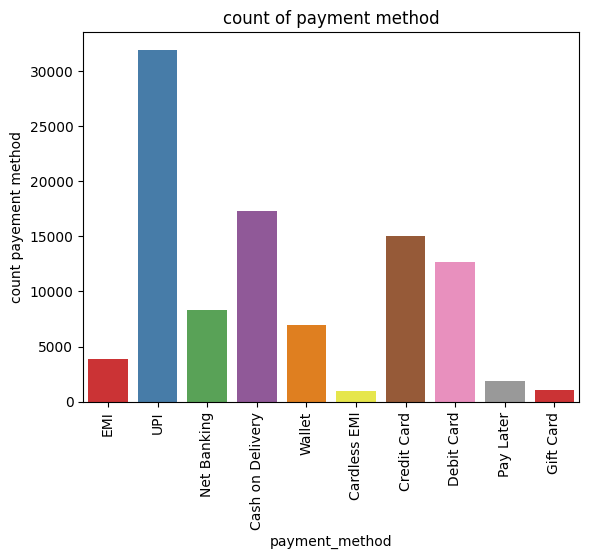

In [214]:
sns.countplot(data=pay,x="payment_method",palette="Set1")
pls.xticks(rotation=90)
pls.xlabel("payment_method")
pls.ylabel("count payement method")
pls.title("count of payment method")
pls.show()

In [215]:
# payment status
pay["payment_status"].value_counts()

,count
payment_status,
Success,82137
Refunded,10690
Failed,5068
Not Charged,1876
Pending,229


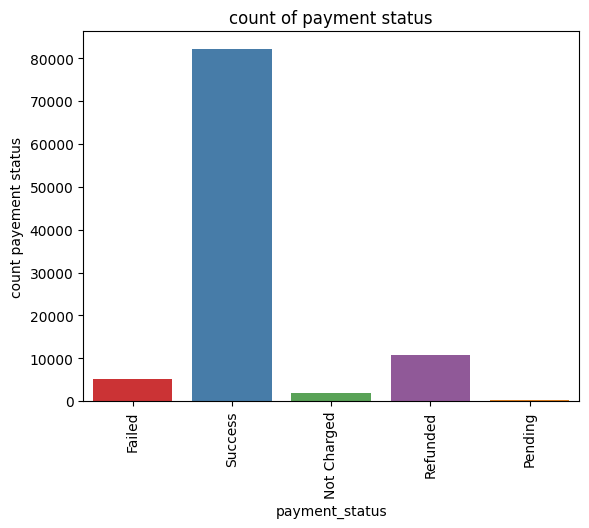

In [216]:
# payment status
sns.countplot(data=pay,x="payment_status",palette="Set1")
pls.xticks(rotation=90)
pls.xlabel("payment_status")
pls.ylabel("count payement status")
pls.title("count of payment status")
pls.show()

In [218]:
df22 = pay.groupby("payment_method")["payment_status"].value_counts()
df22

payment_method    payment_status
Cardless EMI      Success             773
                  Refunded             90
                  Failed               73
                  Pending               3
Cash on Delivery  Success           14176
                  Not Charged        1876
                  Refunded           1177
                  Pending              45
Credit Card       Success           12335
                  Refunded           1802
                  Failed              891
                  Pending              35
Debit Card        Success           10373
                  Refunded           1484
                  Failed              794
                  Pending              31
EMI               Success            3233
                  Refunded            405
                  Failed              247
                  Pending               4
Gift Card         Success             863
                  Refunded            118
                  Failed               63
                  Pending               2
Net Banking       Success            6854
                  Refunded            961
                  Failed              488
                  Pending              19
Pay Later         Success            1515
                  Refunded            186
                  Failed              119
                  Pending               5
UPI               Success           26247
                  Refunded           3691
                  Failed             1967
                  Pending              66
Wallet            Success            5768
                  Refunded            776
                  Failed              426
                  Pending              19
Name: count, dtype: int64

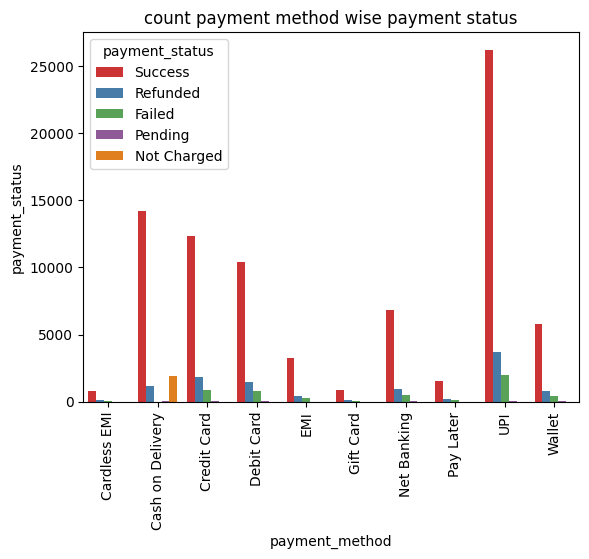

In [219]:
df22 = pay.groupby("payment_method")["payment_status"].value_counts().reset_index()
sns.barplot(data=df22,x="payment_method",y="count",hue="payment_status",palette="Set1")
pls.xticks(rotation=90)
pls.xlabel("payment_method")
pls.ylabel("payment_status")
pls.title("count payment method wise payment status")
pls.show()

In [220]:
pay.head()

,payment_id,order_id,payment_date,payment_method,payment_status,amount_paid,transaction_fee,refund_amount,payment_year,payment_month,payment_day
0,PAY1000000,ORD1000000,2025-08-16,EMI,Failed,0.0,0.0,0.0,2025,8,16
1,PAY1000001,ORD1000001,2023-02-12,UPI,Success,4998.0,0.0,0.0,2023,2,12
2,PAY1000002,ORD1000002,2024-12-14,Net Banking,Success,867.3,0.0,0.0,2024,12,14
3,PAY1000003,ORD1000003,2025-11-23,Cash on Delivery,Not Charged,0.0,0.0,0.0,2025,11,23
4,PAY1000004,ORD1000004,2025-07-27,Cash on Delivery,Not Charged,0.0,0.0,0.0,2025,7,27


In [221]:
df23 = pay.groupby("payment_method")["transaction_fee"].sum()
df23

,transaction_fee
payment_method,
Cardless EMI,308705.53
Cash on Delivery,0.00
Credit Card,5493952.12
Debit Card,0.00
EMI,1344263.26
Gift Card,0.00
Net Banking,0.00
Pay Later,0.00
UPI,0.00


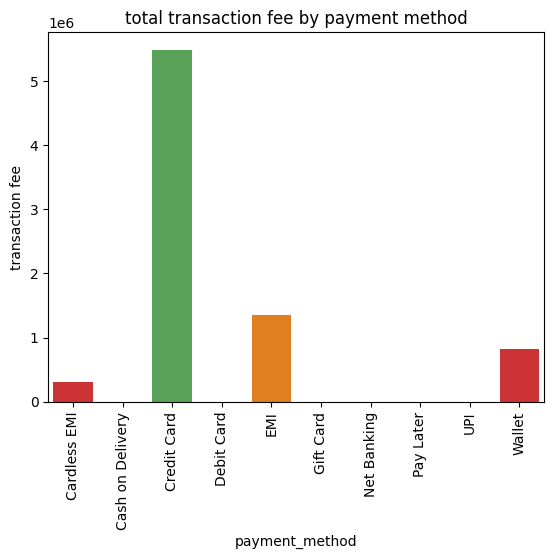

In [223]:
df23 = pay.groupby("payment_method")["transaction_fee"].sum().reset_index()
sns.barplot(data=df23,x="payment_method",y="transaction_fee",palette="Set1")
pls.xticks(rotation=90)
pls.xlabel("payment_method")
pls.ylabel("transaction fee")
pls.title("total transaction fee by payment method")
pls.show()

In [224]:
df24 = pay.groupby("payment_status")["transaction_fee"].sum()
df24

,transaction_fee
payment_status,
Failed,0.00
Not Charged,0.00
Pending,0.00
Refunded,936060.13
Success,7029436.16


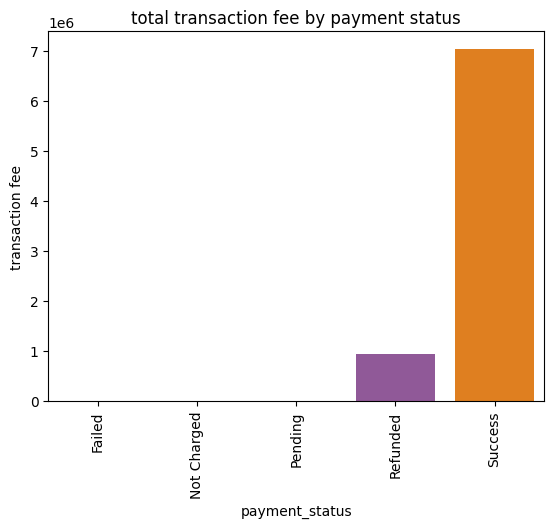

In [225]:
df23 = pay.groupby("payment_status")["transaction_fee"].sum().reset_index()
sns.barplot(data=df23,x="payment_status",y="transaction_fee",palette="Set1")
pls.xticks(rotation=90)
pls.xlabel("payment_status")
pls.ylabel("transaction fee")
pls.title("total transaction fee by payment status")
pls.show()

In [227]:
# year by payment status
pay.groupby("payment_year")["payment_status"].value_counts()

payment_year  payment_status
2023          Success           21944
              Refunded           2898
              Failed             1387
              Not Charged         478
2024          Success           22065
              Refunded           2833
              Failed             1333
              Not Charged         502
2025          Success           38128
              Refunded           4959
              Failed             2348
              Not Charged         896
              Pending             229
Name: count, dtype: int64

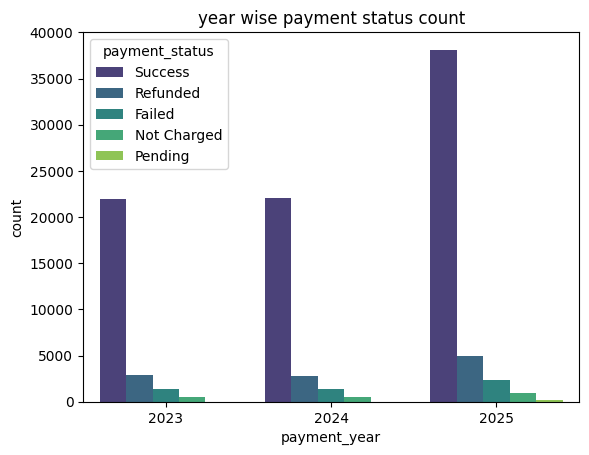

In [228]:
df25 = pay.groupby("payment_year")["payment_status"].value_counts().reset_index()
sns.barplot(data=df25,x="payment_year",y="count",hue="payment_status",palette="viridis")
pls.xlabel("payment_year")
pls.ylabel("count")
pls.title("year wise payment status count")
pls.show()

In [229]:
# year by payment method
pay.groupby("payment_year")["payment_method"].value_counts()

payment_year  payment_method  
2023          UPI                  8489
              Cash on Delivery     4702
              Credit Card          4029
              Debit Card           3318
              Net Banking          2162
              Wallet               1882
              EMI                  1080
              Pay Later             514
              Gift Card             289
              Cardless EMI          242
2024          UPI                  8496
              Cash on Delivery     4725
              Credit Card          4070
              Debit Card           3438
              Net Banking          2105
              Wallet               1853
              EMI                  1043
              Pay Later             459
              Gift Card             282
              Cardless EMI          262
2025          UPI                 14986
              Cash on Delivery     7847
              Credit Card          6964
              Debit Card           5926
              Net Banking          4055
              Wallet               3254
              EMI                  1766
              Pay Later             852
              Gift Card             475
              Cardless EMI          435
Name: count, dtype: int64

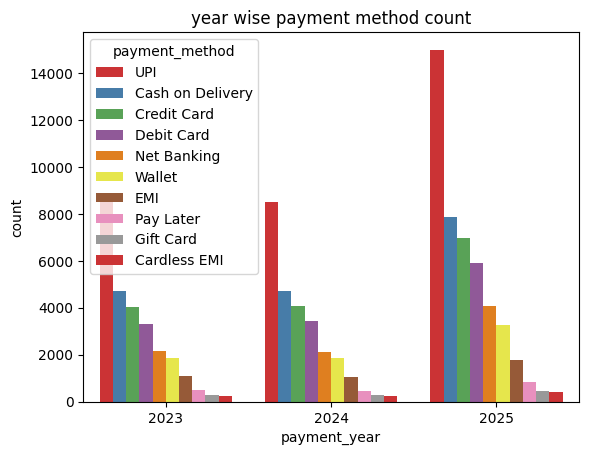

In [231]:
df25 = pay.groupby("payment_year")["payment_method"].value_counts().reset_index()
sns.barplot(data=df25,x="payment_year",y="count",hue="payment_method",palette="Set1")
pls.xlabel("payment_year")
pls.ylabel("count")
pls.title("year wise payment method count")
pls.show()

In [233]:
# month by payment method
pay.groupby("payment_month")["payment_method"].value_counts()

payment_month  payment_method  
1              UPI                 1688
               Cash on Delivery     895
               Credit Card          799
               Debit Card           654
               Net Banking          435
                                   ... 
12             Wallet              1083
               EMI                  576
               Pay Later            283
               Gift Card            166
               Cardless EMI         143
Name: count, Length: 120, dtype: int64

In [237]:
r.head()

,return_id,order_id,customer_id,product_id,return_date,return_reason,refund_amount,return_status,return_year,return_month,return_day
0,RET100000,ORD1000009,CUST117396,PROD10073,2024-05-28,Changed mind,2094.4,Refund Completed,2024,5,28
1,RET100001,ORD1000019,CUST122124,PROD10077,2023-12-30,Product damaged,1040.0,Refund Completed,2023,12,30
2,RET100002,ORD1000019,CUST122124,PROD10451,2024-01-06,Wrong product,0.0,Pending,2024,1,6
3,RET100003,ORD1000019,CUST122124,PROD10043,2024-01-05,Quality issue,15104.0,Refund Completed,2024,1,5
4,RET100004,ORD1000028,CUST101962,PROD10171,2023-06-19,Changed mind,0.0,Pending,2023,6,19


<Axes: xlabel='return_year'>

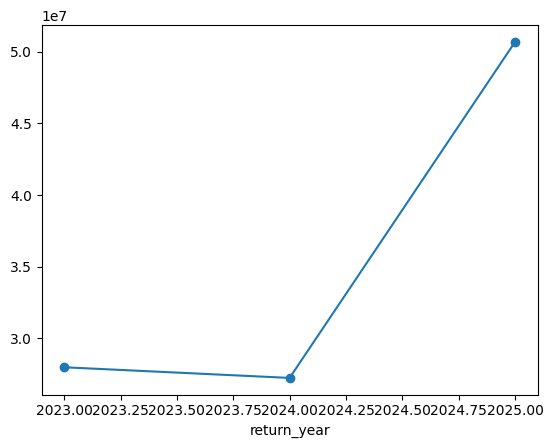

In [239]:
df28 = r.groupby("return_year")["refund_amount"].sum()
df28.plot(kind="line",marker="o")


<Axes: xlabel='return_month'>

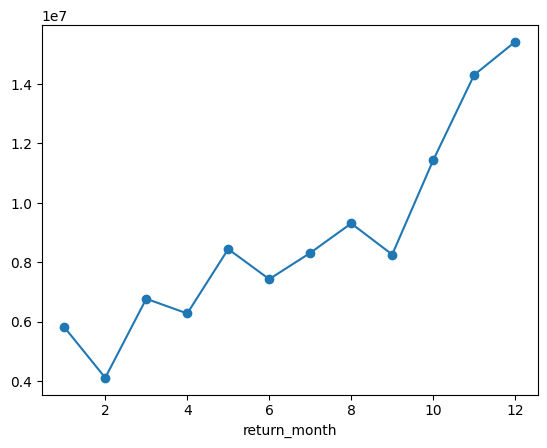

In [240]:
df28 = r.groupby("return_month")["refund_amount"].sum()
df28.plot(kind="line",marker="o")

In [241]:
sp.head()

,shipment_id,order_id,warehouse_city,delivery_city,shipping_method,dispatch_date,expected_delivery_date,actual_delivery_date,delivery_days,delivery_status,delayed_flag,expected_delivery_year,expected_delivery_month,expected_delivery_day,actual_delivery_year,actual_delivery_month,actual_delivery_day,dispatch_year,dispatch_month,dispatch_day
0,SHIP1000000,ORD1000001,Chennai,Thiruvananthapuram,Economy/Surface,2023-02-11,2023-02-19,2023-02-17,6.0,Delivered,0,2023,2,19,2023.0,2.0,17.0,2023,2,11
1,SHIP1000001,ORD1000002,Mumbai,Nagpur,Economy/Surface,2024-12-15,2024-12-23,2024-12-26,11.0,Delivered,1,2024,12,23,2024.0,12.0,26.0,2024,12,15
2,SHIP1000002,ORD1000005,Chennai,Coimbatore,Standard,2025-01-09,2025-01-13,2025-01-12,3.0,Delivered,0,2025,1,13,2025.0,1.0,12.0,2025,1,9
3,SHIP1000003,ORD1000006,Delhi-NCR (Gurugram),Noida,Same-Day,2025-05-26,2025-05-26,2025-05-27,1.0,Delivered,1,2025,5,26,2025.0,5.0,27.0,2025,5,26
4,SHIP1000004,ORD1000007,Chennai,Thiruvananthapuram,Express,2025-10-04,2025-10-06,NaT,NaN,Cancelled in Transit,0,2025,10,6,NaN,NaN,NaN,2025,10,4
